In [1]:
!pip install -q mne-icalabel pywavelets scikit-learn seaborn tqdm pandas
# !pip freeze > "requirements.txt"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.8/48.8 MB 23.4 MB/s eta 0:00:00


In [2]:
import os
import random

# Locks hash seeds and backend mathematics to guarantee 100% reproducible AUROC metrics
os.environ['PYTHONHASHSEED'] = '42'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['XLA_FLAGS'] = '--xla_gpu_autotune_level=0'

import time
import logging
import scipy.io
import numpy as np
import pandas as pd
import pickle
import hashlib
import json
from mne_icalabel import label_components
import warnings
import mne
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tqdm import tqdm
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Dense, SpatialDropout2D, BatchNormalization, 
    LayerNormalization, MultiHeadAttention, Add, GlobalAveragePooling1D, 
    Reshape, Embedding, Dropout, Concatenate, Layer
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, Callback, CSVLogger

# ==============================================================================
# 1. STRICT DETERMINISM & FILE SYSTEM INITIALIZATION
# ==============================================================================
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

# redundant:
# tf.random.set_seed(42)
# random.seed(42)
# np.random.seed(42)

DIRS = {
    "logs": "outputs/logs",
    "models": "outputs/models",
    "plots_preproc": "outputs/plots/preprocessing",
    "plots_train": "outputs/plots/training",
    "plots_eval": "outputs/plots/evaluation"
}

best_weights_path = os.path.join(DIRS["models"], "best_paper_hybrid.weights.h5")

for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

class Formatter(logging.Formatter):
    def format(self, record):
        if record.msg.startswith('\n'):
            return record.msg
        return super().format(record)

logger = logging.getLogger()
logger.setLevel(logging.INFO)
if logger.hasHandlers():
    logger.handlers.clear()

ch = logging.StreamHandler()
ch.setFormatter(Formatter('%(asctime)s - %(levelname)s - %(message)s'))
fh = logging.FileHandler(os.path.join(DIRS["logs"], "experiment_master_log.txt"), mode='w')
fh.setFormatter(Formatter('%(asctime)s - %(levelname)s - %(message)s'))
logger.addHandler(ch)
logger.addHandler(fh)

In [3]:
# ==============================================================================
# 2. CENTRALIZED HYPERPARAMETERS
# ==============================================================================
class Config:
    DATA_DIR = r'/kaggle/input/datasets/paperbreak/adhd-eeg/data'
    
    # --- CACHING --- # data save and load
    # Set to a folder in /kaggle/working to save/load within the session, 
    # or point to a "/kaggle/input/your-saved-cache-dataset" path to load pre-computed data
    # PREPROC_CACHE_DIR = "outputs/preprocessed_cache" # for re-data preprocessing
    PREPROC_CACHE_DIR = "/kaggle/input/datasets/papapopeye/adhd-eeg-preprocessed"
    
    SFREQ = 128
    WINDOW_SIZE = 256
    CH_NAMES = ['Fz', 'Cz', 'Pz', 'C3', 'T3', 'C4', 'T4', 'Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'P3', 'P4', 'T5', 'T6', 'O1', 'O2']
    CH_TYPES = ['eeg'] * len(CH_NAMES)
    
    scaling_factor = 1e-7
    
    FILTER_L_FREQ = 1.0
    FILTER_H_FREQ = 40.0
    ICA_COMPONENTS = 15
    
    TRAIN_OVERLAP = 0.5
    TEST_OVERLAP = 0.0

    # bad electorde removal and interpolation
    BAD_THRESHOLD = 1e-10

    # ptp rejection threshold
    REJECTION_THRESHOLD = 150e-6
    # REJECTION_THRESHOLD = 15000e-6 # use to remove PTP rejection
    
    # --- MASTER MIXUP CONTROLS ---
    ENABLE_MIXUP = False            # Master toggle (Set False to disable Mixup completely)
    CURRICULUM_MIXUP = True         # If True, delays Mixup to learn sharp boundaries first
    MIXUP_START_EPOCH = 6          # Epoch to activate Mixup (if curriculum is enabled)
    MIXUP_ALPHA = 0.5               # Milder alpha for smoothing ROC

    # --- VISUALS ---
    DISPLAY_INLINE_PLOTS = True

    # --- GPU STFT PARAMETERS ---
    STFT_FRAME_LENGTH = 128
    STFT_FRAME_STEP = 8
    STFT_FFT_LENGTH = 128

    # --- HYBRID ARCHITECTURE ---
    D_MODEL = 64
    VIT_BLOCKS = 3
    VIT_HEADS = 4
    
    # --- TRAINING LOOP ---
    BATCH_SIZE = 64
    EPOCHS = 20
    LEARNING_RATE = 1e-4
    WEIGHT_DECAY = 1e-2
    GRADIENT_CLIPNORM = 1.0
    PATIENCE_ES = 8
    PATIENCE_LR = 2

    # --- LOSS LANDSCAPE ---
    FOCAL_GAMMA = 2.0
    FOCAL_ALPHA = [0.5, 0.5]

logging.info(f"Pipeline Initialized. Outputs will be saved to /outputs/")

2026-10-23 19:11:21,270 - INFO - Pipeline Initialized. Outputs will be saved to /outputs/


In [4]:
# ==============================================================================
# 3. CLINICAL DATA INGESTION, CACHING & VISUALIZATION
# ==============================================================================
def save_clinical_eeg_plot(raw, filtered, cleaned, zscored, subj_id, label, plot_inline):
    time_axis = np.arange(raw.shape[1]) / Config.SFREQ
    
    # ==============================================================================
    # FIGURE 1: Clinical Offset Overview
    # ==============================================================================
    fig1, axes1 = plt.subplots(4, 1, figsize=(18, 24), sharex=True)
    offset_raw = 100e-6   
    offset_z = 6.0        
    
    for i, ch_name in enumerate(Config.CH_NAMES):
        axes1[0].plot(time_axis, raw[i, :] + (i * offset_raw), color='grey', linewidth=0.6)
        axes1[1].plot(time_axis, filtered[i, :] + (i * offset_raw), color='blue', linewidth=0.6)
        axes1[2].plot(time_axis, cleaned[i, :] + (i * offset_raw), color='green', linewidth=0.6)
        axes1[3].plot(time_axis, zscored[i, :] + (i * offset_z), color='purple', linewidth=0.6)
    
    axes1[0].set_title(f'1. Raw EEG Ingestion (19 Channels) - Subject: {subj_id} ({label})')
    axes1[1].set_title('2. Bandpass Filtered (1-40 Hz)')
    axes1[2].set_title('3. ICA Reconstructed Artifact Removal')
    axes1[3].set_title('4. True Z-Score Normalized (Clinical Offset)')
    axes1[3].set_xlabel('Time (Seconds)')
    
    for ax, offset in zip(axes1[:3], [offset_raw]*3):
        ax.set_yticks(np.arange(19) * offset)
        ax.set_yticklabels(Config.CH_NAMES)
        ax.set_ylim(-offset, 19 * offset)
        
    axes1[3].set_yticks(np.arange(19) * offset_z)
    axes1[3].set_yticklabels(Config.CH_NAMES)
    axes1[3].set_ylim(-offset_z, 19 * offset_z)
    
    fig1.tight_layout()
    fig1.savefig(os.path.join(DIRS["plots_preproc"], f"preproc_overview_{label}_{subj_id}.png"), dpi=200)
    
    # ==============================================================================
    # FIGURE 2: Individual Channel Y-Axis Deep Dive (TIGHTENED)
    # ==============================================================================
    # 1. Reduced figsize height from 30 to 14
    fig2, axes2 = plt.subplots(19, 1, figsize=(18, 14), sharex=True)
    
    for i, ch_name in enumerate(Config.CH_NAMES):
        axes2[i].plot(time_axis, cleaned[i, :] * 1e6, color='green', linewidth=0.8)
        
        # 2. Reduced labelpad and font size slightly so labels don't crash into each other
        axes2[i].set_ylabel(f"{ch_name}\n(µV)", rotation=0, labelpad=20, va='center', fontweight='bold', fontsize=9)
        axes2[i].grid(True, axis='y', linestyle='--', alpha=0.7)
        axes2[i].axhline(y=75, color='red', linestyle=':', alpha=0.5)
        axes2[i].axhline(y=-75, color='red', linestyle=':', alpha=0.5)
        axes2[i].autoscale(enable=True, axis='y', tight=False)
        
        # 3. Hide the top and bottom spines of the subplots to reduce visual clutter in tight mode
        if i < 18:
            axes2[i].spines['bottom'].set_visible(False)
        if i > 0:
            axes2[i].spines['top'].set_visible(False)

    axes2[0].set_title(f'Post-ICA Cleaned EEG Voltage (µV) - Subject: {subj_id} ({label})')
    axes2[-1].set_xlabel('Time (Seconds)')
    
    fig2.tight_layout()
    # 4. Squashed the blank space between rows from 0.3 down to 0.05
    fig2.subplots_adjust(hspace=0.05) 
    fig2.savefig(os.path.join(DIRS["plots_preproc"], f"preproc_voltage_yaxes_{label}_{subj_id}.png"), dpi=200)
    
    if plot_inline:
        plt.show() 
        
    plt.close(fig1)
    plt.close(fig2)

montage = mne.channels.make_standard_montage('standard_1020')

# 1. Generate a deterministic hash of all preprocessing hyperparameters
preproc_signature = {
    "sfreq": Config.SFREQ,
    "window_size": Config.WINDOW_SIZE,
    "ch_names": Config.CH_NAMES,
    "scaling_factor": Config.scaling_factor,
    "l_freq": Config.FILTER_L_FREQ,
    "h_freq": Config.FILTER_H_FREQ,
    "ica_components": Config.ICA_COMPONENTS,
    "ica_seed": 42, # Add explicit ICA seed, final fixes
    "bad_threshold": Config.BAD_THRESHOLD,
    "rejection_threshold": Config.REJECTION_THRESHOLD,
    "car_reference": True,
    "iclabel_prob_thresh": 0.70
}
sig_hash = hashlib.md5(json.dumps(preproc_signature, sort_keys=True).encode()).hexdigest()[:10]
cache_filename = f"adhd_eeg_preproc_{sig_hash}.pkl"
cache_filepath = os.path.join(Config.PREPROC_CACHE_DIR, cache_filename)

# 2. Check if valid cached data already exists
cache_loaded = False
if os.path.exists(cache_filepath):
    logging.info(f"\n[CACHE HIT] Found verified preprocessed dataset at: {cache_filepath}")
    try:
        with open(cache_filepath, "rb") as f:
            cache_payload = pickle.load(f)
            
        # Verify integrity of the loaded payload
        if cache_payload.get("signature") == preproc_signature:
            raw_data_dict = cache_payload["raw_data_dict"]
            groups_dict = cache_payload["groups_dict"]
            signal_durations = cache_payload["signal_durations"]
            ica_exclusion_counts = cache_payload["ica_exclusion_counts"]
            total_ptp_rejected_sec3 = cache_payload["total_ptp_rejected_sec3"]
            zscore_failsafe_count = cache_payload["zscore_failsafe_count"]
            
            total_loaded = len(raw_data_dict['Control']) + len(raw_data_dict['ADHD'])
            assert total_loaded == 121, f"Expected 121 subjects, found {total_loaded}!"
            
            logging.info(f"[CACHE INTEGRITY PASSED] Loaded {len(raw_data_dict['Control'])} Control & {len(raw_data_dict['ADHD'])} ADHD subjects in float32.")
            cache_loaded = True
        else:
            logging.warning("[CACHE MISMATCH] Hyperparameter signature mismatch. Re-running preprocessing...")
    except Exception as e:
        logging.warning(f"[CACHE CORRUPTED] Failed to load cache ({e}). Re-running preprocessing from scratch...")

# 3. If no valid cache exists, run full MNE + ICLabel preprocessing and save
if not cache_loaded:
    raw_data_dict = {'ADHD': [], 'Control': []}
    groups_dict = {'ADHD': [], 'Control': []}
    
    all_files = []
    for folder in sorted([f.path for f in os.scandir(Config.DATA_DIR) if f.is_dir()]):
        label_str = 'ADHD' if 'adhd' in os.path.basename(folder).lower() else 'Control'
        for filename in sorted(os.listdir(folder)):
            if filename.endswith('.mat'):
                all_files.append((folder, filename, label_str))

    logging.info(f"\n[CACHE MISS] Discovered {len(all_files)} clinical arrays. Initiating MNE + ICA pre-processing...")

    plotted_adhd = False
    plotted_control = False
    ica_exclusion_counts = []
    signal_durations = []
    zscore_failsafe_count = 0
    total_ptp_rejected_sec3 = 0

    for folder, filename, label_str in all_files:
        logging.info(f"\n[PRE-PROCESS STARTED] for patient {filename}")
        mat = scipy.io.loadmat(os.path.join(folder, filename))
        subject_id = [k for k in mat.keys() if not k.startswith('__')][-1]
        
        data = mat[subject_id].T.astype(np.float32) * Config.scaling_factor
        raw_array = np.copy(data)
        signal_durations.append(data.shape[1] / Config.SFREQ)

        info = mne.create_info(ch_names=Config.CH_NAMES, sfreq=Config.SFREQ, ch_types=Config.CH_TYPES)
        raw = mne.io.RawArray(data, info, verbose=False)
        
        channel_renaming = {'T3': 'T7', 'T4': 'T8', 'T5': 'P7', 'T6': 'P8'}
        raw.rename_channels(channel_renaming)
        raw.set_montage(montage)

        variances = np.var(raw.get_data(), axis=1)
        bad_idx = np.where(variances < Config.BAD_THRESHOLD)[0]
        if len(bad_idx) > 0:
            raw.info['bads'] = [raw.ch_names[i] for i in bad_idx]
            raw.interpolate_bads(reset_bads=True, verbose=False)
            logging.warning(f"[INTERPOLATION] Reconstructed {len(bad_idx)} flatlined channels for subject {subject_id}")

        raw.filter(l_freq=Config.FILTER_L_FREQ, h_freq=Config.FILTER_H_FREQ, fir_design='firwin', verbose=False)
        
        # Apply Common Average Reference (CAR) required by ICLabel
        raw.set_eeg_reference('average', projection=False, verbose=False)
        filtered_array = raw.get_data().astype(np.float32)
        
        ica = mne.preprocessing.ICA(n_components=Config.ICA_COMPONENTS, method='infomax', fit_params=dict(extended=True), random_state=42)
        ica.fit(raw, verbose=False)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=RuntimeWarning)
            labels = label_components(raw, ica, method='iclabel')
            
        # Exclude artifacts only if confidence > 70%
        ica.exclude = [
            i for i, (label, prob) in enumerate(zip(labels['labels'], labels['y_pred_proba'])) 
            if label in ['eye blink', 'heart beat', 'muscle artifact'] and prob > 0.70
        ]
        
        num_excluded = len(ica.exclude)
        ica_exclusion_counts.append(num_excluded)
        logging.warning(f"[ICA WARNING] {num_excluded} artifacts detected for subject {subject_id}.")
            
        clean_data = ica.apply(raw.copy(), verbose=False).get_data().astype(np.float32)

        # ROBUST Z-SCORING PRE-SCAN WITH TELEMETRY
        step = Config.WINDOW_SIZE
        clean_windows = []
        patient_ptp_rejected = 0
        patient_total_windows = 0
        for start in range(0, clean_data.shape[1] - Config.WINDOW_SIZE + 1, step):
            patient_total_windows += 1
            win = clean_data[:, start:start+Config.WINDOW_SIZE]
            if not np.any(np.abs(win) > Config.REJECTION_THRESHOLD): 
                clean_windows.append(win)
            else:
                patient_ptp_rejected += 1
                
        total_ptp_rejected_sec3 += patient_ptp_rejected
        
        if patient_ptp_rejected > 0:
            logging.info(f"[PTP PRE-SCAN] Subject {subject_id}: Flagged {patient_ptp_rejected} out of {patient_total_windows} windows for hardware noise.")
                
        if clean_windows:
            clean_arr = np.array(clean_windows, dtype=np.float32)
            p_mean = np.mean(clean_arr, axis=(0, 2)).reshape(19, 1)
            p_std = np.std(clean_arr, axis=(0, 2)).reshape(19, 1) + 1e-8
        else:
            logging.warning(f"[Z-SCORE FAILSAFE] Subject {subject_id} had NO windows under 150 µV. Using noisy global fallback.")
            zscore_failsafe_count += 1
            p_mean = np.mean(clean_data, axis=1, keepdims=True)
            p_std = np.std(clean_data, axis=1, keepdims=True) + 1e-8
            
        zscored_data = ((clean_data - p_mean) / p_std).astype(np.float32)
        
        if label_str == 'ADHD' and not plotted_adhd:
            logging.info(f"[VISUAL VERIFICATION] Generating Pre-Processing Overview for ADHD patient {subject_id}")
            save_clinical_eeg_plot(raw_array, filtered_array, clean_data, zscored_data, subject_id, label_str, Config.DISPLAY_INLINE_PLOTS)
            plotted_adhd = True
        elif label_str == 'Control' and not plotted_control:
            logging.info(f"[VISUAL VERIFICATION] Generating Pre-Processing Overview for Control patient {subject_id}")
            save_clinical_eeg_plot(raw_array, filtered_array, clean_data, zscored_data, subject_id, label_str, Config.DISPLAY_INLINE_PLOTS)
            plotted_control = True
            
        raw_data_dict[label_str].append((clean_data, zscored_data, subject_id))
        groups_dict[label_str].append(subject_id)

    # 4. Save to disk atomically (write to .tmp then rename to prevent partial-write corruption)
    try:
        os.makedirs(Config.PREPROC_CACHE_DIR, exist_ok=True)
        temp_filepath = cache_filepath + ".tmp"
        cache_payload = {
            "signature": preproc_signature,
            "raw_data_dict": raw_data_dict,
            "groups_dict": groups_dict,
            "signal_durations": signal_durations,
            "ica_exclusion_counts": ica_exclusion_counts,
            "total_ptp_rejected_sec3": total_ptp_rejected_sec3,
            "zscore_failsafe_count": zscore_failsafe_count
        }
        with open(temp_filepath, "wb") as f:
            pickle.dump(cache_payload, f, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(temp_filepath, cache_filepath)
        logging.info(f"\n[CACHE SAVED] Successfully persisted preprocessed dataset to: {cache_filepath}")
    except OSError as e:
        logging.warning(f"\n[CACHE SAVE SKIPPED] Could not write to {Config.PREPROC_CACHE_DIR} (read-only path?): {e}")

avg_duration = float(np.mean(signal_durations))
avg_excluded = float(np.mean(ica_exclusion_counts))
logging.info(f"\n[PREPROCESSING COMPLETE] Ready with {len(raw_data_dict['Control'])} Control & {len(raw_data_dict['ADHD'])} ADHD subjects.")
logging.info(f"[DATA STATS] Average EEG recording duration: {avg_duration:.2f} seconds per patient.")
logging.info(f"[ICA STATS] Autonomously removed an average of {avg_excluded:.2f} artifact components per patient.")
logging.info(f"[PTP STATS] Pre-scan identified and bypassed a total of {total_ptp_rejected_sec3} corrupted windows across all patients.")

# --- GROUP-LEVEL EEG DURATION DESCRIPTIVE STATISTICS TABLE ---
adhd_durs = np.array([clean.shape[1] / Config.SFREQ for clean, _, _ in raw_data_dict['ADHD']], dtype=np.float64)
ctrl_durs = np.array([clean.shape[1] / Config.SFREQ for clean, _, _ in raw_data_dict['Control']], dtype=np.float64)

duration_table = pd.DataFrame({
    'Cohort': ['Control (Neurotypical)', 'ADHD (Clinical Cohort)', 'Combined Cohort'],
    'N': [len(ctrl_durs), len(adhd_durs), len(ctrl_durs) + len(adhd_durs)],
    'Mean_Sec': [np.mean(ctrl_durs), np.mean(adhd_durs), np.mean(signal_durations)],
    'Std_Sec': [np.std(ctrl_durs), np.std(adhd_durs), np.std(signal_durations)],
    'Median_Sec': [np.median(ctrl_durs), np.median(adhd_durs), np.median(signal_durations)],
    'Min_Sec': [np.min(ctrl_durs), np.min(adhd_durs), np.min(signal_durations)],
    'Max_Sec': [np.max(ctrl_durs), np.max(adhd_durs), np.max(signal_durations)],
    'Total_Hours': [np.sum(ctrl_durs) / 3600.0, np.sum(adhd_durs) / 3600.0, np.sum(signal_durations) / 3600.0]
})

duration_table_path = os.path.join(DIRS["logs"], "cohort_eeg_duration_table.csv")
duration_table.to_csv(duration_table_path, index=False)

logging.info("\n" + "="*80)
logging.info("            CLINICAL COHORT EEG RECORDING DURATION BENCHMARK            ")
logging.info("="*80)
for _, r in duration_table.iterrows():
    logging.info(f"{r['Cohort']:<25} | N={int(r['N']):<3} | {r['Mean_Sec']:.2f} ± {r['Std_Sec']:.2f}s | Median: {r['Median_Sec']:.1f}s | Range: [{r['Min_Sec']:.1f} - {r['Max_Sec']:.1f}s] | Total: {r['Total_Hours']:.2f} hrs")
logging.info("="*80)
logging.info(f"Persisted duration statistics table to: {duration_table_path}")


[CACHE HIT] Found verified preprocessed dataset at: /kaggle/input/datasets/papapopeye/adhd-eeg-preprocessed/adhd_eeg_preproc_d069491967.pkl
2026-10-23 19:11:26,303 - INFO - [CACHE INTEGRITY PASSED] Loaded 60 Control & 61 ADHD subjects in float32.

[PREPROCESSING COMPLETE] Ready with 60 Control & 61 ADHD subjects.
2026-10-23 19:11:26,307 - INFO - [DATA STATS] Average EEG recording duration: 139.87 seconds per patient.
2026-10-23 19:11:26,308 - INFO - [ICA STATS] Autonomously removed an average of 0.03 artifact components per patient.
2026-10-23 19:11:26,309 - INFO - [PTP STATS] Pre-scan identified and bypassed a total of 1187 corrupted windows across all patients.

2026-10-23 19:11:26,323 - INFO -             CLINICAL COHORT EEG RECORDING DURATION BENCHMARK            
2026-10-23 19:11:26,323 - INFO - ================================================================================
2026-10-23 19:11:26,338 - INFO - Control (Neurotypical)    | N=60  | 124.91 ± 29.66s | Median: 122.1s | Ra

2026-10-23 19:11:26,385 - INFO - [ID COLLISION CHECK PASSED] Verified 121 unique subject IDs across 121 total patient recordings.

[SPLIT VERIFICATION] Subjects -> Train: 85 | Val: 18 | Test: 18 | Total: 121
2026-10-23 19:11:26,443 - INFO - [LEAKAGE CHECK] PASSED: 100% Patient Isolation. Zero overlapping subjects across folds.
2026-10-23 19:11:28,513 - INFO - [AMPLITUDE REJECTION] Dropped 1822 corrupted windows out of 12020 total.
2026-10-23 19:11:28,645 - INFO - [VISUAL VERIFICATION] Generating 19-panel Final Tensor Plot for Control patient v107


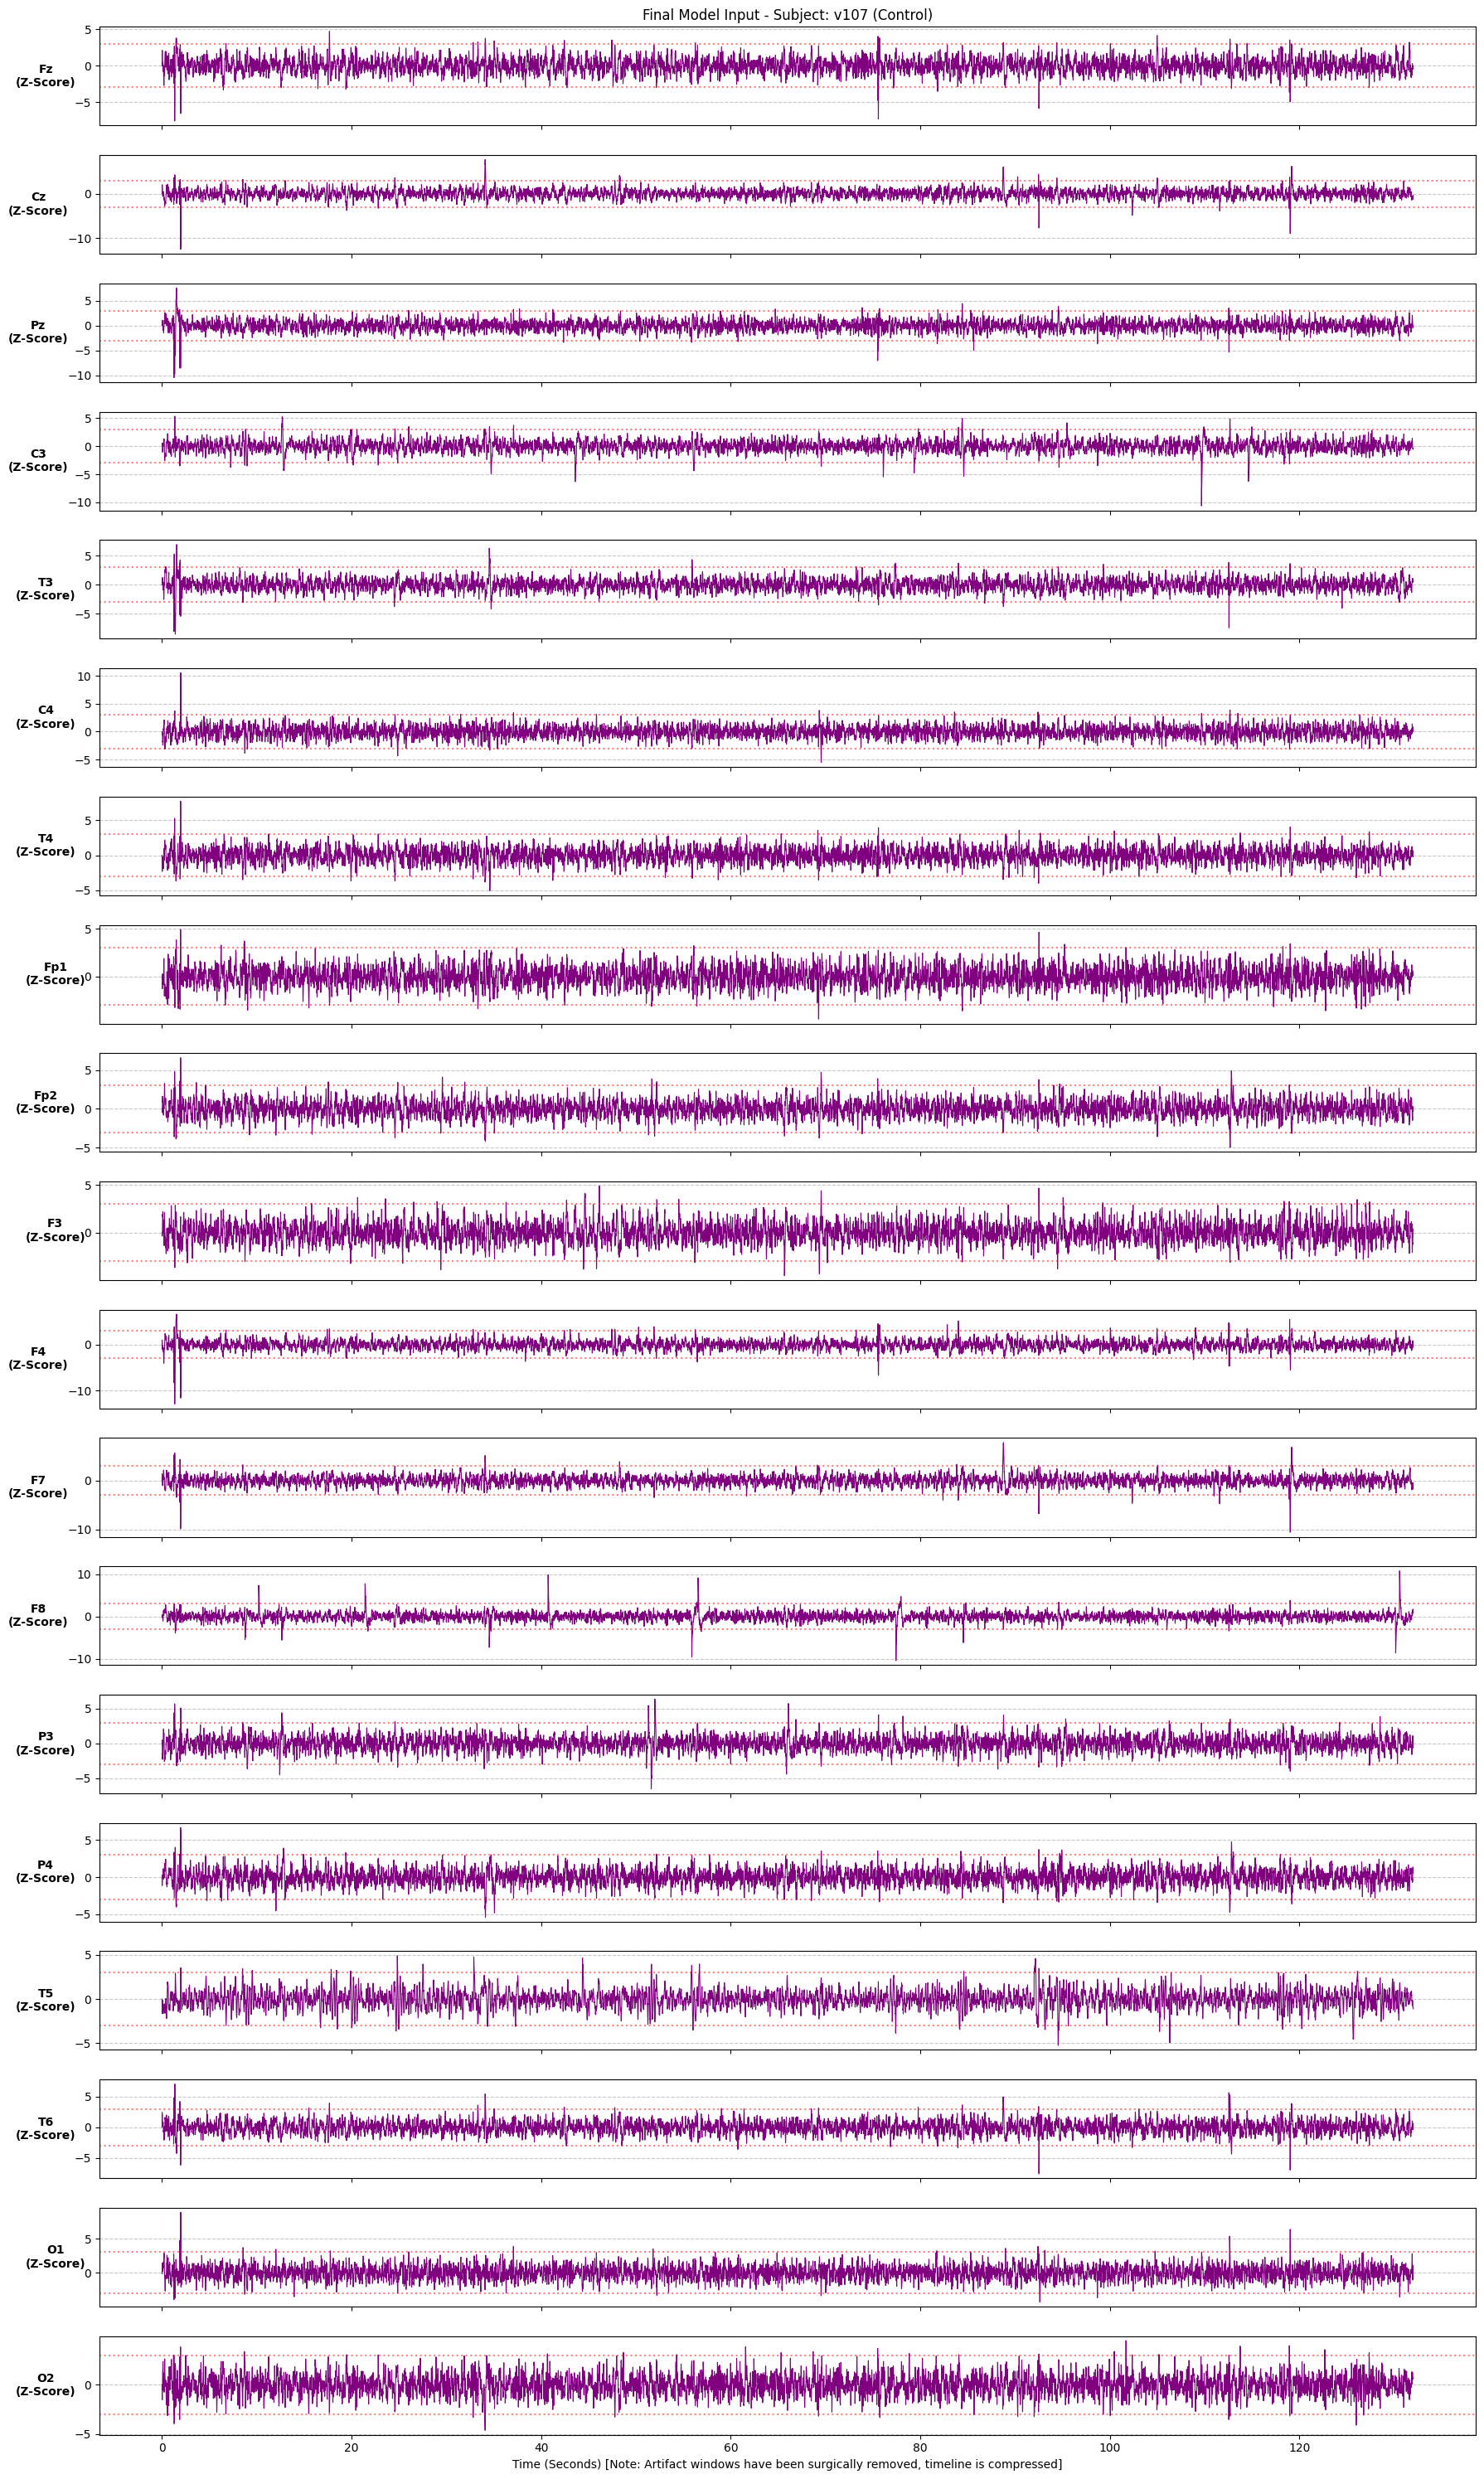

2026-10-23 19:11:33,257 - INFO - [VISUAL VERIFICATION] Generating 19-panel Final Tensor Plot for ADHD patient v14p


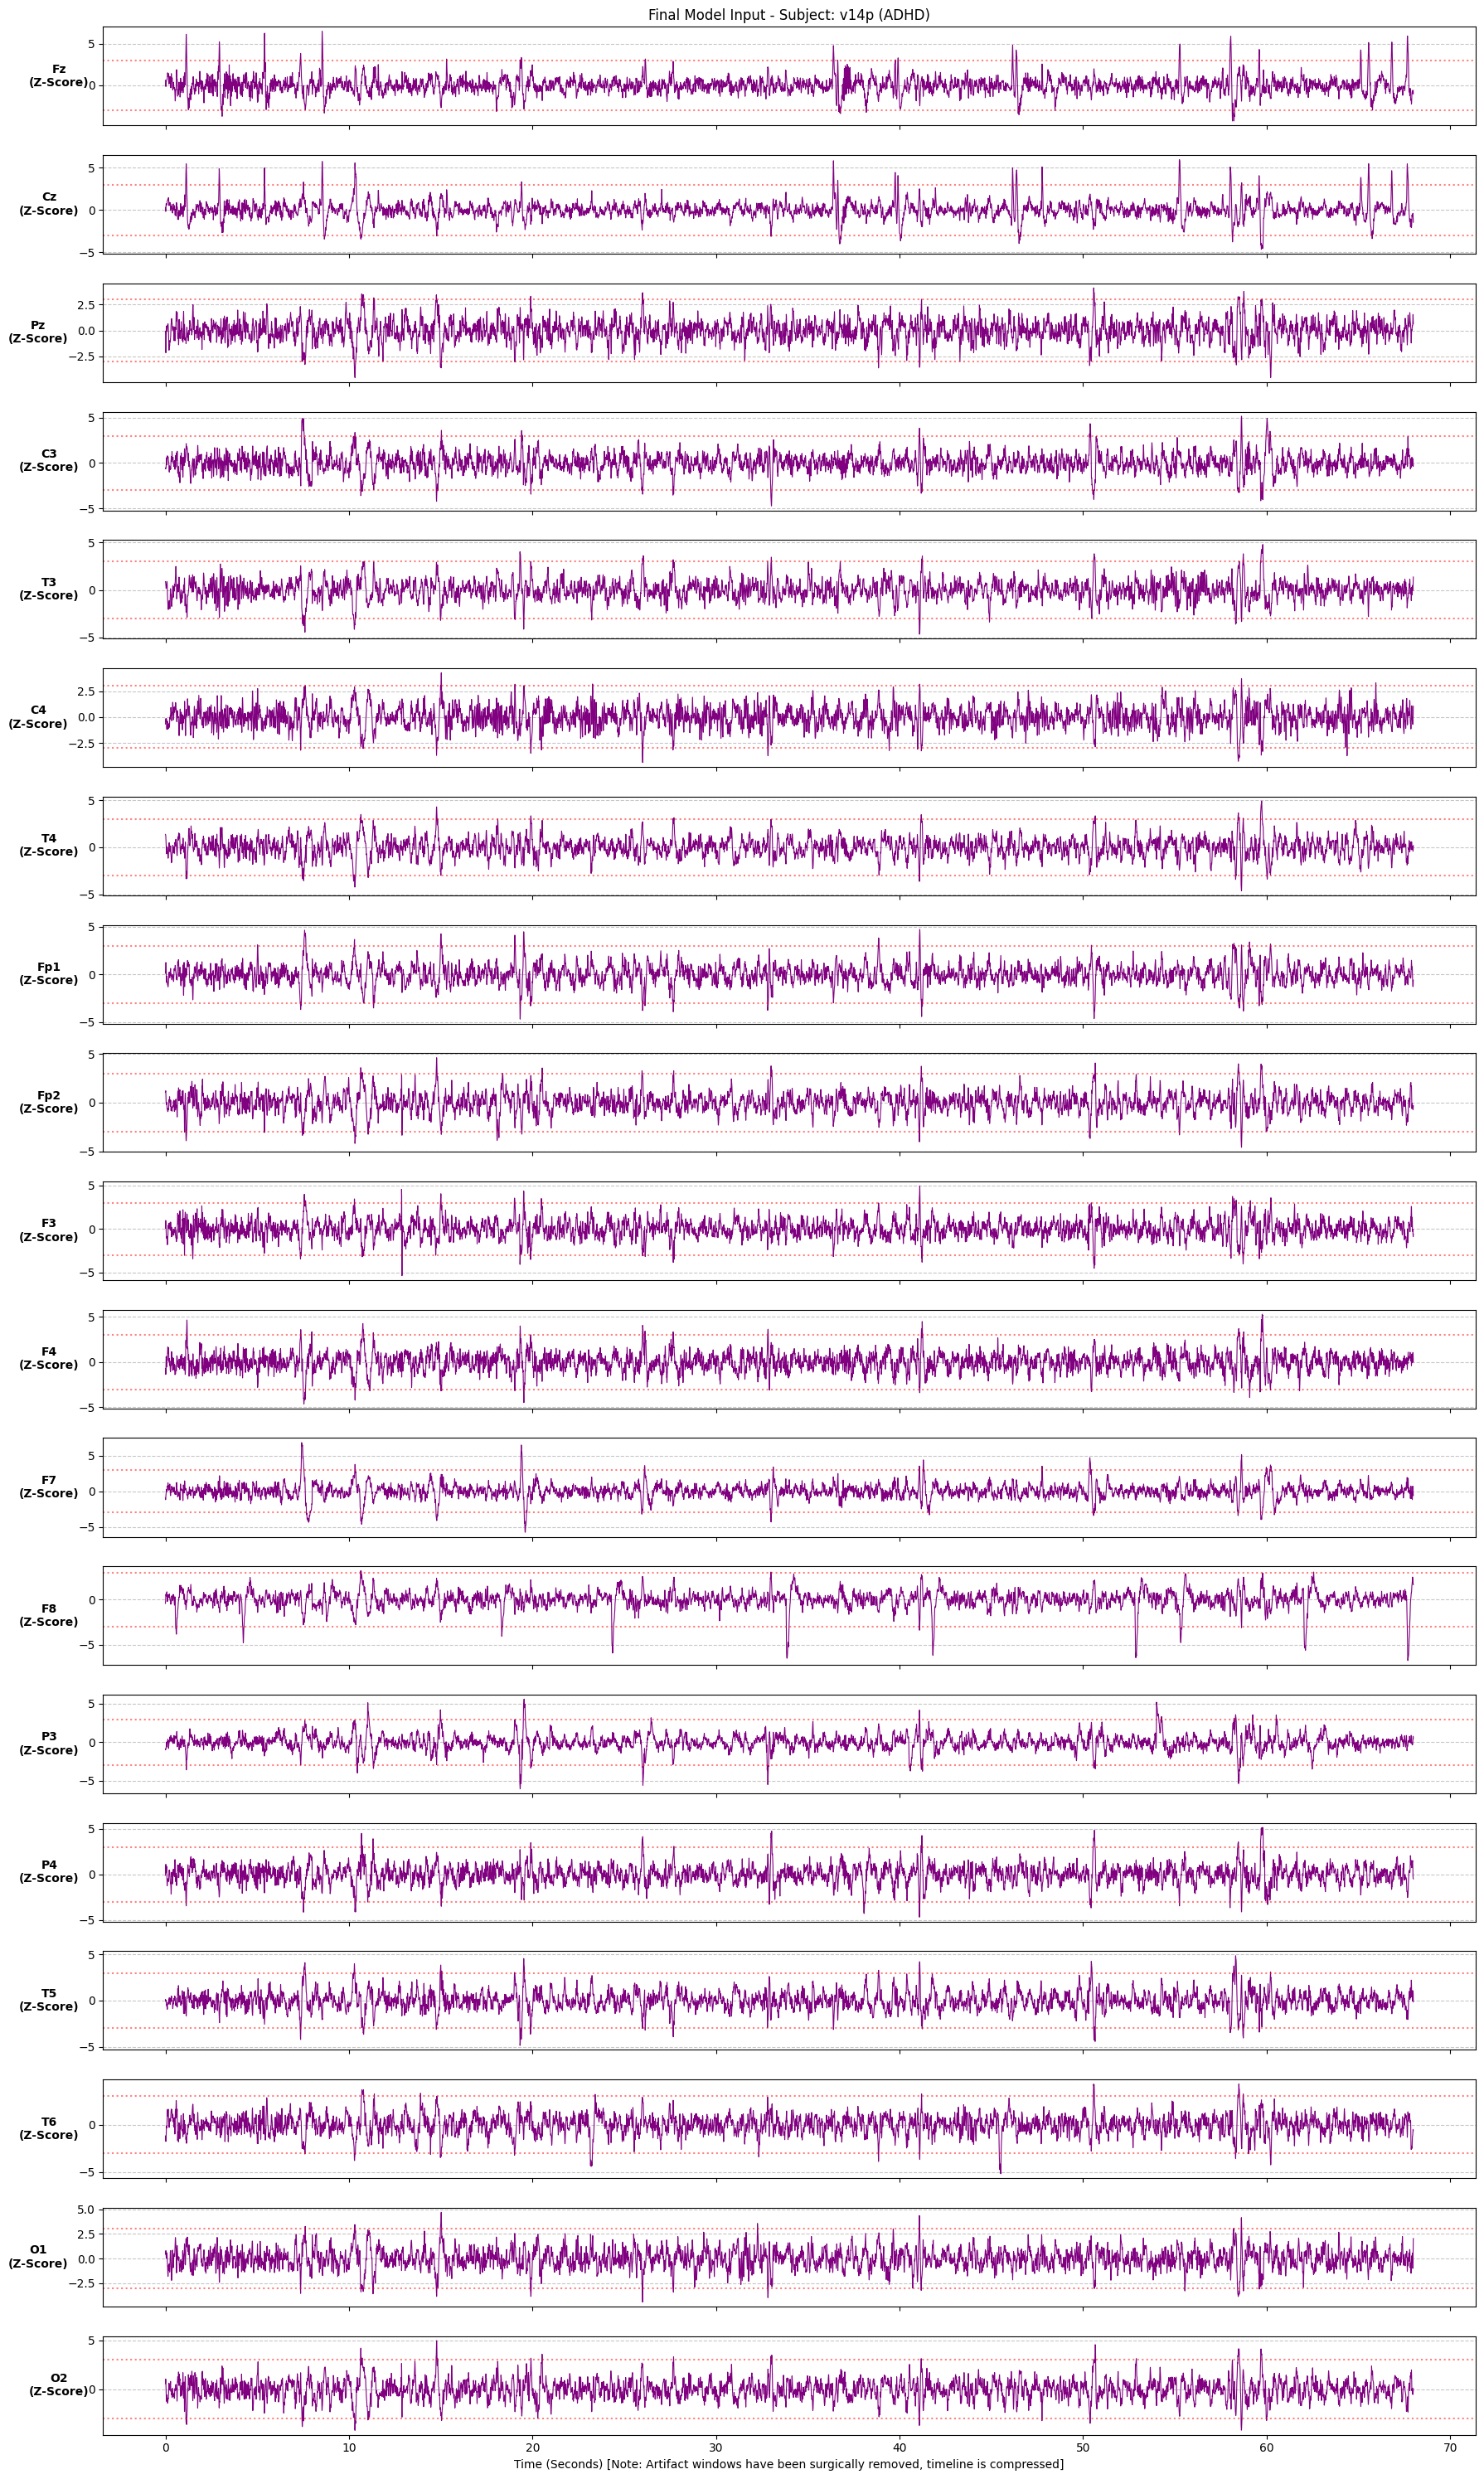

2026-10-23 19:11:37,472 - INFO - [AMPLITUDE REJECTION] Dropped 139 corrupted windows out of 1247 total.
2026-10-23 19:11:37,657 - INFO - [AMPLITUDE REJECTION] Dropped 122 corrupted windows out of 1122 total.
2026-10-23 19:11:37,666 - INFO - [TENSOR SHAPES] Train: (10198, 256, 19) | Val: (1108, 256, 19) | Test: (1000, 256, 19)
2026-10-23 19:11:37,666 - INFO - [CONNECTIVITY SHAPES] Train: (10198, 171) | Val: (1108, 171) | Test: (1000, 171)
2026-10-23 19:11:37,671 - INFO - [SPLIT INTEGRITY PASSED] All subjects retained at least one clean window past ptp rejection.
2026-10-23 19:11:37,673 - INFO - [CLASS BALANCE] Control Windows: 4494 | ADHD Windows: 5704
2026-10-23 19:11:37,674 - INFO - [FOCAL LOSS] Normalized Alpha Multipliers: [np.float64(0.5593253579133163), np.float64(0.4406746420866837)]
2026-10-23 19:11:37,737 - INFO - [SHUFFLE VERIFICATION] Perfect global shuffle applied to training tensors. Determinism locked.


In [5]:
# ==============================================================================
# 4. SUBJECT-ISOLATED SPLITTING & WINDOWING (TRAIN / VAL / TEST)
# ==============================================================================
all_X_raw, all_y, all_groups = [], [], []
for label_val, label_str in enumerate(['Control', 'ADHD']):
    for data_volts, data_zscored, subj in raw_data_dict[label_str]:
        all_X_raw.append((data_volts, data_zscored))
        all_y.append(label_val)
        all_groups.append(subj)

total_subjects = len(all_groups)
total_unique_groups = len(set(all_groups))

assert total_unique_groups == total_subjects, \
    f"ID Collision Risk: Loaded {total_subjects} subjects, but only found {total_unique_groups} unique subject IDs! Check if files share internal .mat keys."

assert total_unique_groups == 121, \
    f"Dataset Integrity Error: Expected exactly 121 subjects, but found {total_unique_groups}!"

logging.info(f"[ID COLLISION CHECK PASSED] Verified {total_unique_groups} unique subject IDs across {total_subjects} total patient recordings.")

# 7-fold StratifiedGroupKFold: 5 folds (~71%) Train, 1 fold (~14.5%) Val, 1 fold (~14.5%) Test
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
folds = list(sgkf.split(all_X_raw, all_y, all_groups))

val_idx = folds[0][1]
test_idx = folds[1][1]
train_idx = np.concatenate([folds[i][1] for i in range(2, 7)])

train_subjs = set([all_groups[i] for i in train_idx])
val_subjs = set([all_groups[i] for i in val_idx])
test_subjs = set([all_groups[i] for i in test_idx])

logging.info(f"\n[SPLIT VERIFICATION] Subjects -> Train: {len(train_subjs)} | Val: {len(val_subjs)} | Test: {len(test_subjs)} | Total: {len(set(all_groups))}")

if not train_subjs.intersection(val_subjs) and not train_subjs.intersection(test_subjs) and not val_subjs.intersection(test_subjs):
    logging.info("[LEAKAGE CHECK] PASSED: 100% Patient Isolation. Zero overlapping subjects across folds.")
else:
    logging.error("[LEAKAGE CHECK] FAILED: Patient overlap detected!")

def plot_final_clean_patient(zscored_data, subj_id, label, plot_inline=Config.DISPLAY_INLINE_PLOTS):
    """Plots the actual Z-scored arrays exactly as they are fed to the CNN-ViT model."""
    time_axis = np.arange(zscored_data.shape[1]) / Config.SFREQ
    
    fig, axes = plt.subplots(19, 1, figsize=(18, 30), sharex=True)
    
    for i, ch_name in enumerate(Config.CH_NAMES):
        axes[i].plot(time_axis, zscored_data[i, :], color='purple', linewidth=0.8)
        axes[i].set_ylabel(f"{ch_name}\n(Z-Score)", rotation=0, labelpad=25, va='center', fontweight='bold')
        axes[i].grid(True, axis='y', linestyle='--', alpha=0.7)
        
        axes[i].axhline(y=3, color='red', linestyle=':', alpha=0.5)
        axes[i].axhline(y=-3, color='red', linestyle=':', alpha=0.5)
        axes[i].autoscale(enable=True, axis='y', tight=False)

    axes[0].set_title(f'Final Model Input - Subject: {subj_id} ({label})')
    axes[-1].set_xlabel('Time (Seconds) [Note: Artifact windows have been surgically removed, timeline is compressed]')
    
    fig.tight_layout()
    fig.subplots_adjust(hspace=0.3) 
    fig.savefig(os.path.join(DIRS["plots_preproc"], f"final_model_input_{label}_{subj_id}.png"), dpi=200)
    
    if plot_inline:
        plt.show() 
    plt.close(fig)

plotted_final_models = {'ADHD': False, 'Control': False}

def segment_data_with_subjects(indices, overlap):
    X_seg, conn_seg, y_seg, subj_seg = [], [], [], []
    step_size = int(Config.WINDOW_SIZE * (1 - overlap))
    REJECTION_THRESHOLD = Config.REJECTION_THRESHOLD 
    upper_tri_idx = np.triu_indices(len(Config.CH_NAMES), k=1)
    
    dropped_windows = 0
    total_windows = 0

    for idx in indices:
        d_volts, d_zscored = all_X_raw[idx]
        label = all_y[idx]
        subj = all_groups[idx]
        patient_clean_zscored = []
        
        for start in range(0, d_volts.shape[1] - Config.WINDOW_SIZE + 1, step_size):
            total_windows += 1
            win_volts = d_volts[:, start:start+Config.WINDOW_SIZE]
            
            if np.any(np.abs(win_volts) > REJECTION_THRESHOLD):
                dropped_windows += 1
                continue 
            
            win_zscored = d_zscored[:, start:start+Config.WINDOW_SIZE]
            patient_clean_zscored.append(win_zscored)
            
            # Precompute Pearson functional connectivity on the authentic, unmixed window
            with np.errstate(divide='ignore', invalid='ignore'):
                corr_matrix = np.corrcoef(win_zscored)
                corr_matrix = np.nan_to_num(corr_matrix, nan=0.0)
            conn_vector = corr_matrix[upper_tri_idx].astype(np.float32)
            
            # Store window in (WINDOW_SIZE, CHANNELS) layout matching model input
            X_seg.append(win_zscored.T.astype(np.float32))
            conn_seg.append(conn_vector)
            y_seg.append(label)
            subj_seg.append(subj)
            
        # VISUAL VERIFICATION: Only execute plot logic on 0% overlap sets to prevent time distortion
        if patient_clean_zscored and overlap == 0.0:
            label_str = 'ADHD' if label == 1 else 'Control'
            if not plotted_final_models[label_str]:
                patient_clean_zscored = np.array(patient_clean_zscored) 
                continuous_clean_signal = np.transpose(patient_clean_zscored, (1, 0, 2)).reshape(19, -1)
                
                logging.info(f"[VISUAL VERIFICATION] Generating 19-panel Final Tensor Plot for {label_str} patient {subj}")
                plot_final_clean_patient(continuous_clean_signal, subj, label_str)
                plotted_final_models[label_str] = True
            
    logging.info(f"[AMPLITUDE REJECTION] Dropped {dropped_windows} corrupted windows out of {total_windows} total.")
    return np.array(X_seg), np.array(conn_seg), np.array(y_seg), np.array(subj_seg)

# Precompute both raw tensors and connectivity features simultaneously
X_train_raw, conn_train, y_train_labels, train_subject_ids = segment_data_with_subjects(train_idx, Config.TRAIN_OVERLAP)
X_val_raw, conn_val, y_val_labels, val_subject_ids = segment_data_with_subjects(val_idx, Config.TEST_OVERLAP)
X_test_raw, conn_test, y_test_labels, test_subject_ids = segment_data_with_subjects(test_idx, Config.TEST_OVERLAP)

logging.info(f"[TENSOR SHAPES] Train: {X_train_raw.shape} | Val: {X_val_raw.shape} | Test: {X_test_raw.shape}")
logging.info(f"[CONNECTIVITY SHAPES] Train: {conn_train.shape} | Val: {conn_val.shape} | Test: {conn_test.shape}")

# Vanishing subject verification
for split_name, subjs_set, subj_seg_arr in [
    ('Train', train_subjs, train_subject_ids),
    ('Val', val_subjs, val_subject_ids), 
    ('Test', test_subjs, test_subject_ids)
]:
    if len(subjs_set) > 0 and len(subj_seg_arr) > 0:
        remaining_subjs = set(subj_seg_arr)
        vanished = subjs_set - remaining_subjs
        assert len(vanished) == 0, f"Critical Error: {len(vanished)} subjects vanished in {split_name} split due to 100% window rejection: {vanished}"

logging.info("[SPLIT INTEGRITY PASSED] All subjects retained at least one clean window past ptp rejection.")

y_train_cat = to_categorical(y_train_labels).astype(np.float32)
y_val_cat = to_categorical(y_val_labels).astype(np.float32)
y_test_cat = to_categorical(y_test_labels).astype(np.float32)

train_counts = np.bincount(y_train_labels)
total_train = len(y_train_labels)
Config.FOCAL_ALPHA = [total_train / (2.0 * train_counts[0]), total_train / (2.0 * train_counts[1])]
alpha_sum = sum(Config.FOCAL_ALPHA)
Config.FOCAL_ALPHA = [a / alpha_sum for a in Config.FOCAL_ALPHA]

logging.info(f"[CLASS BALANCE] Control Windows: {train_counts[0]} | ADHD Windows: {train_counts[1]}")
logging.info(f"[FOCAL LOSS] Normalized Alpha Multipliers: {Config.FOCAL_ALPHA}")

# Global deterministic shuffle across all three training matrices
shuffle_indices = np.random.permutation(len(X_train_raw))
X_train_raw = X_train_raw[shuffle_indices]
conn_train = conn_train[shuffle_indices]
y_train_cat = y_train_cat[shuffle_indices]
logging.info("[SHUFFLE VERIFICATION] Perfect global shuffle applied to training tensors. Determinism locked.")

In [6]:
# ==============================================================================
# 5. ASYNCHRONOUS TF.DATA PIPELINE & DETERMINISTIC MIXUP
# ==============================================================================
# TF variable ensures dynamic activation in graph mode across training epochs
mixup_active = tf.Variable(
    False if (Config.ENABLE_MIXUP and Config.CURRICULUM_MIXUP) else Config.ENABLE_MIXUP,
    dtype=tf.bool,
    trainable=False
)

class CurriculumMixupCallback(Callback):
    def on_epoch_begin(self, epoch, logs=None):
        if Config.ENABLE_MIXUP and Config.CURRICULUM_MIXUP:
            if epoch >= Config.MIXUP_START_EPOCH and not mixup_active.numpy():
                mixup_active.assign(True)
                logging.info(f"\n[CURRICULUM TRIGGER] Epoch {epoch+1}: Cross-Subject Mixup ACTIVATED")

class ResourceLoggingCallback(Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()
        try:
            tf.config.experimental.reset_memory_stats('GPU:0')
        except ValueError:
            pass 

    def on_epoch_end(self, epoch, logs=None):
        epoch_time = time.time() - self.epoch_start_time
        try:
            mem_info = tf.config.experimental.get_memory_info('GPU:0')
            peak_vram_mb = mem_info['peak'] / (1024 ** 2)
        except ValueError:
            peak_vram_mb = 0.0

        logging.info(f"[RESOURCE TRACKER] Epoch {epoch + 1} | Duration: {epoch_time:.2f} sec | Peak VRAM: {peak_vram_mb:.2f} MB")
        if logs is not None:
            logs['epoch_time_s'] = epoch_time
            logs['peak_vram_mb'] = peak_vram_mb

def deterministic_tf_mixup(batch_raw, batch_conn, batch_y):
    """
    Applies Mixup strictly via native TensorFlow graph operations.
    Solves Phase Destruction by blending precomputed connectivity matrices directly.
    Guarantees bit-for-bit determinism under tf.keras.utils.set_random_seed(42).
    """
    def do_mixup():
        batch_size = tf.shape(batch_raw)[0]
        indices = tf.random.shuffle(tf.range(batch_size))
        
        # Sample Beta(alpha, alpha) via independent Gamma variables: X / (X + Y)
        alpha = tf.constant(Config.MIXUP_ALPHA, dtype=tf.float32)
        gamma1 = tf.random.gamma(shape=[batch_size, 1, 1], alpha=alpha, beta=1.0)
        gamma2 = tf.random.gamma(shape=[batch_size, 1, 1], alpha=alpha, beta=1.0)
        lam = gamma1 / (gamma1 + gamma2)
        
        # 1. Mix raw EEG: (B, 256, 19)
        raw_shuffled = tf.gather(batch_raw, indices)
        mixed_raw = (lam * batch_raw) + ((1.0 - lam) * raw_shuffled)
        
        # 2. Mix connectivity matrix linearly (preserves graph properties, prevents phase cancellation)
        lam_2d = tf.reshape(lam, [batch_size, 1])
        conn_shuffled = tf.gather(batch_conn, indices)
        mixed_conn = (lam_2d * batch_conn) + ((1.0 - lam_2d) * conn_shuffled)
        
        # 3. Mix one-hot label vectors
        y_shuffled = tf.gather(batch_y, indices)
        mixed_y = (lam_2d * batch_y) + ((1.0 - lam_2d) * y_shuffled)
        
        return (mixed_raw, mixed_conn), mixed_y

    def no_mixup():
        return (batch_raw, batch_conn), batch_y

    return tf.cond(mixup_active, do_mixup, no_mixup)

# Training pipeline with native graph mixup
train_dataset = tf.data.Dataset.from_tensor_slices((X_train_raw, conn_train, y_train_cat))
train_dataset = train_dataset.shuffle(10000, seed=42).batch(Config.BATCH_SIZE, drop_remainder=False)
train_dataset = train_dataset.map(deterministic_tf_mixup, num_parallel_calls=tf.data.AUTOTUNE, deterministic=True).prefetch(tf.data.AUTOTUNE)

# Validation and Test pipelines directly yield ((raw_input, conn_input), label)
val_dataset = tf.data.Dataset.from_tensor_slices(((X_val_raw, conn_val), y_val_cat))
val_dataset = val_dataset.batch(Config.BATCH_SIZE, drop_remainder=False).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices(((X_test_raw, conn_test), y_test_cat))
test_dataset = test_dataset.batch(Config.BATCH_SIZE, drop_remainder=False).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1792782701.421822      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792782701.425156      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [7]:
# ==============================================================================
# 6. GPU-STFT -> CNN -> ViT -> PEARSON
# ==============================================================================
@tf.keras.utils.register_keras_serializable()
class GPU_STFT_Layer(Layer):
    def __init__(self, frame_length=128, frame_step=8, fft_length=128, **kwargs):
        super().__init__(**kwargs)
        self.frame_length = frame_length
        self.frame_step = frame_step
        self.fft_length = fft_length

    def call(self, inputs):
        x = tf.transpose(inputs, perm=[0, 2, 1])
        stft_complex = tf.signal.stft(
            x, frame_length=self.frame_length, frame_step=self.frame_step, fft_length=self.fft_length
        )
        magnitude = tf.abs(stft_complex)[:, :, :, :41]
        magnitude_db = 20.0 * (tf.math.log(magnitude + 1e-8) / tf.math.log(10.0))
        return tf.transpose(magnitude_db, perm=[0, 3, 2, 1])

    def get_config(self):
        config = super().get_config()
        config.update({
            "frame_length": self.frame_length,
            "frame_step": self.frame_step,
            "fft_length": self.fft_length
        })
        return config

@tf.keras.utils.register_keras_serializable()
class LayerScale(Layer):
    def __init__(self, init_values=1e-2, **kwargs): 
        super().__init__(**kwargs)
        self.init_values = init_values

    def build(self, input_shape):
        self.gamma = self.add_weight(
            name="gamma", shape=(input_shape[-1],),
            initializer=tf.keras.initializers.Constant(self.init_values), trainable=True
        )

    def call(self, inputs):
        return inputs * self.gamma

    def get_config(self):
        config = super().get_config()
        config.update({"init_values": self.init_values})
        return config

@tf.keras.utils.register_keras_serializable()
class PositionalEmbedding(Layer):
    def __init__(self, d_model, max_patches=256, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model
        self.max_patches = max_patches
        # Hardcode a safe upper bound (256) so changing window/pooling sizes 
        # will never trigger out-of-bounds shape errors or serialization mismatches.
        self.pos_emb = Embedding(input_dim=max_patches, output_dim=d_model)

    def call(self, inputs):
        # Dynamically grab the actual sequence length from the incoming tensor shape
        num_patches = tf.shape(inputs)[1]
        positions = tf.range(start=0, limit=num_patches, delta=1)
        return inputs + self.pos_emb(positions)
    
    def get_config(self):
        config = super().get_config()
        config.update({"d_model": self.d_model, "max_patches": self.max_patches})
        return config

def build_paper_hybrid_model(raw_shape=(256, 19), conn_shape=(171,), num_classes=2):
    raw_input = Input(shape=raw_shape, name="Raw_EEG_Input")
    
    # Output shape: (Batch, 41, 17, 19)
    x = GPU_STFT_Layer(Config.STFT_FRAME_LENGTH, Config.STFT_FRAME_STEP, Config.STFT_FFT_LENGTH)(raw_input)
    x = BatchNormalization()(x)
    
    # Block 1: Pool both Freq and Time -> (Batch, 20, 8, 16)
    x = Conv2D(16, (1, 7), activation='relu', padding='same')(x) 
    x = BatchNormalization()(x)
    x = Conv2D(16, (7, 1), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 2))(x) 
    x = SpatialDropout2D(0.3)(x) 
    
    # Block 2: Pool Freq only (2, 1) to preserve Time -> (Batch, 10, 8, 32)
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 1))(x)
    x = SpatialDropout2D(0.3)(x)
    
    # Block 3: Pool Freq only (2, 1) to preserve Time -> (Batch, 5, 8, 64)
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D((2, 1))(x)
    x = SpatialDropout2D(0.4)(x)
    
    # Patch Projection: strides=(1, 1) keeps grid at 5x8 = 40 patches -> (Batch, 40, 64)
    x = Conv2D(Config.D_MODEL, kernel_size=(3, 3), strides=(1, 1), padding='same', activation='relu')(x)
    _, h, w, c = x.shape
    num_patches = h * w

    x = Reshape((num_patches, c))(x)
    x = PositionalEmbedding(d_model=Config.D_MODEL)(x)
    
    for _ in range(Config.VIT_BLOCKS):
        norm1 = LayerNormalization(epsilon=1e-6)(x)
        attn = MultiHeadAttention(num_heads=Config.VIT_HEADS, key_dim=32, dropout=0.4)(norm1, norm1)
        attn = LayerScale(init_values=1e-2)(attn)
        x1 = Add()([x, attn])
        
        norm2 = LayerNormalization(epsilon=1e-6)(x1)
        ffn = Dense(Config.D_MODEL * 2, activation="gelu")(norm2)
        ffn = Dropout(0.4)(ffn)
        ffn = Dense(Config.D_MODEL)(ffn)
        ffn = LayerScale(init_values=1e-2)(ffn)
        x = Add()([x1, ffn])
        
    vit_features = GlobalAveragePooling1D()(x)
    vit_features = LayerNormalization(epsilon=1e-6)(vit_features)
    
    conn_input = Input(shape=conn_shape, name="Connectivity_Input")
    conn_features = Dense(32, activation='relu')(conn_input)
    conn_features = BatchNormalization()(conn_features)
    conn_features = Dropout(0.3)(conn_features)
    
    merged = Concatenate()([vit_features, conn_features])
    merged = Dense(32, activation='gelu')(merged)
    merged = Dropout(0.5)(merged)
    outputs = Dense(num_classes, activation='softmax')(merged)
    
    return Model(inputs=[raw_input, conn_input], outputs=outputs, name="IEEE_Hybrid_Architecture")

model = build_paper_hybrid_model()

def categorical_focal_loss(alpha, gamma=2.0):
    alpha = tf.constant(alpha, dtype=tf.float32)
    def focal_loss_fn(y_true, y_pred):
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1. - epsilon)
        cross_entropy = -y_true * tf.math.log(y_pred)
        weight = alpha * y_true * tf.math.pow((1 - y_pred), gamma) 
        loss = weight * cross_entropy
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))
    return focal_loss_fn

model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=Config.LEARNING_RATE, weight_decay=Config.WEIGHT_DECAY, clipnorm=Config.GRADIENT_CLIPNORM),
    loss=categorical_focal_loss(alpha=Config.FOCAL_ALPHA, gamma=Config.FOCAL_GAMMA), 
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)], 
    jit_compile=False 
)

class HeartbeatCheckpoint(Callback):
    """Saves the entire model graph and weights at a specified epoch interval."""
    def __init__(self, filepath_template, period=5):
        super().__init__()
        self.filepath_template = filepath_template
        self.period = period

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.period == 0:
            save_path = self.filepath_template.format(epoch=epoch + 1)
            self.model.save(save_path)
            logging.info(f"\n[HEARTBEAT] Saved model state at Epoch {epoch + 1} to {save_path}")

callbacks = [
    ResourceLoggingCallback(),
    CurriculumMixupCallback(),
    # EarlyStopping(monitor='val_auc', mode='max', patience=Config.PATIENCE_ES, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_auc', mode='max', factor=0.5, patience=Config.PATIENCE_LR, min_lr=1e-6, verbose=1),
    ModelCheckpoint(best_weights_path, monitor='val_auc', mode='max', save_best_only=True, save_weights_only=True),
    HeartbeatCheckpoint(os.path.join(DIRS["models"], "heartbeat_epoch_{epoch:02d}.keras"), period=10),
    CSVLogger(os.path.join(DIRS["logs"], "training_metrics.csv"), append=False)
]

train_start_wall_time = time.time()
logging.info("\nCommencing Strict Deterministic Training Sequence...")
history = model.fit(train_dataset, validation_data=val_dataset, epochs=Config.EPOCHS, callbacks=callbacks, verbose=1)
total_training_wall_time = time.time() - train_start_wall_time

model.save(os.path.join(DIRS["models"], "final_epoch_model.keras"))
logging.info(f"[TRAINING COMPLETE] Total Optimization Time: {total_training_wall_time:.2f} seconds ({total_training_wall_time/60.0:.2f} minutes).")

logging.info("Reloading best validation weights for final test evaluation...")
model.load_weights(best_weights_path)


Commencing Strict Deterministic Training Sequence...


Epoch 1/20


2026-10-23 19:11:45.634446: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1792782720.272231      23 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/IEEE_Hybrid_Architecture_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOpti

160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5085 - auc: 0.5088 - loss: 0.2975

2026-10-23 19:12:13,586 - INFO - [RESOURCE TRACKER] Epoch 1 | Duration: 28.14 sec | Peak VRAM: 401.83 MB


160/160 ━━━━━━━━━━━━━━━━━━━━ 28s 48ms/step - accuracy: 0.5216 - auc: 0.5329 - loss: 0.2021 - val_accuracy: 0.6119 - val_auc: 0.4909 - val_loss: 0.9604 - epoch_time_s: 28.1393 - peak_vram_mb: 401.8257 - learning_rate: 1.0000e-04
Epoch 2/20
160/160 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5409 - auc: 0.5815 - loss: 0.1100

... (35 outputs left out)


Epoch 19: ReduceLROnPlateau reducing learning rate to 3.12499992105586e-06.
160/160 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - accuracy: 0.7652 - auc: 0.8529 - loss: 0.0604 - val_accuracy: 0.6516 - val_auc: 0.7118 - val_loss: 0.0770 - epoch_time_s: 6.1345 - peak_vram_mb: 401.8472 - learning_rate: 6.2500e-06
Epoch 20/20
159/160 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.7661 - auc: 0.8555 - loss: 0.0592

2026-10-23 19:14:13,061 - INFO - [RESOURCE TRACKER] Epoch 20 | Duration: 6.14 sec | Peak VRAM: 401.85 MB

[HEARTBEAT] Saved model state at Epoch 20 to outputs/models/heartbeat_epoch_20.keras


160/160 ━━━━━━━━━━━━━━━━━━━━ 6s 40ms/step - accuracy: 0.7671 - auc: 0.8516 - loss: 0.0600 - val_accuracy: 0.6354 - val_auc: 0.7117 - val_loss: 0.0781 - epoch_time_s: 6.1407 - peak_vram_mb: 401.8511 - learning_rate: 3.1250e-06


2026-10-23 19:14:13,618 - INFO - [TRAINING COMPLETE] Total Optimization Time: 147.90 seconds (2.47 minutes).
2026-10-23 19:14:13,619 - INFO - Reloading best validation weights for final test evaluation...



[OPTIMIZATION SUMMARY] Peak Validation State Reached at Epoch 9:
2026-10-23 19:14:14,152 - INFO -  -> Val AUROC:    0.7340
2026-10-23 19:14:14,153 - INFO -  -> Val Accuracy: 0.6823
2026-10-23 19:14:14,153 - INFO -  -> Val Loss:     0.0732
2026-10-23 19:14:14,154 - INFO - Restoring these optimal weights for final evaluation pipeline...


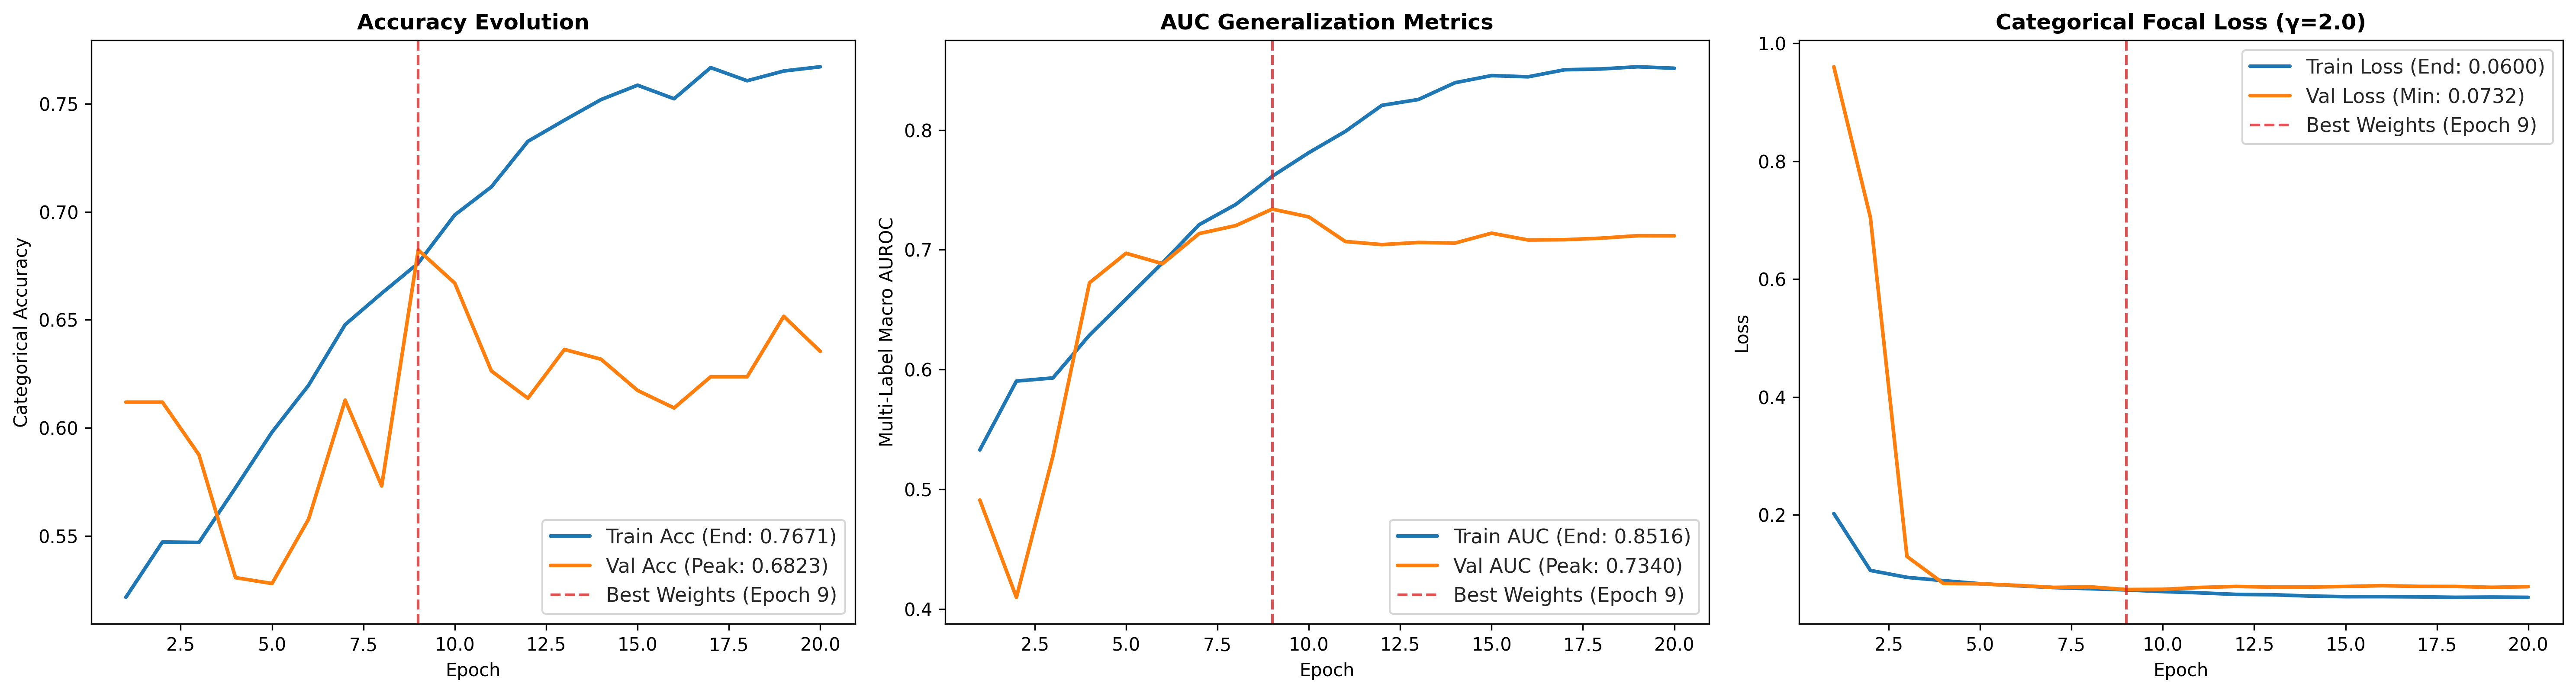

2026-10-23 19:14:16,070 - INFO - Saved high-resolution training dynamics plot to: outputs/plots/training/training_dynamics.png


In [8]:
# ==============================================================================
# 7. ENHANCED TRAINING DYNAMICS VISUALIZATION & PERSISTENCE
# ==============================================================================
# Find the exact epoch where best val_auc was reached
best_epoch_idx = int(np.argmax(history.history['val_auc']))
best_epoch_num = best_epoch_idx + 1
best_val_auc_score = history.history['val_auc'][best_epoch_idx]
best_val_acc_score = history.history['val_accuracy'][best_epoch_idx]
best_val_loss_score = history.history['val_loss'][best_epoch_idx]

logging.info(f"\n[OPTIMIZATION SUMMARY] Peak Validation State Reached at Epoch {best_epoch_num}:")
logging.info(f" -> Val AUROC:    {best_val_auc_score:.4f}")
logging.info(f" -> Val Accuracy: {best_val_acc_score:.4f}")
logging.info(f" -> Val Loss:     {best_val_loss_score:.4f}")
logging.info("Restoring these optimal weights for final evaluation pipeline...")

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), dpi=300)
sns.set_theme(style="whitegrid")

epochs_range = range(1, len(history.history['accuracy']) + 1)

# Panel 1: Accuracy
axes[0].plot(epochs_range, history.history['accuracy'], color='#1f77b4', lw=2, label=f"Train Acc (End: {history.history['accuracy'][-1]:.4f})")
axes[0].plot(epochs_range, history.history['val_accuracy'], color='#ff7f0e', lw=2, label=f"Val Acc (Peak: {best_val_acc_score:.4f})")
axes[0].axvline(x=best_epoch_num, color='#d62728', linestyle='--', alpha=0.8, label=f'Best Weights (Epoch {best_epoch_num})')
axes[0].set_title('Accuracy Evolution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Categorical Accuracy')
axes[0].legend(loc='lower right', frameon=True)

# Panel 2: AUROC
axes[1].plot(epochs_range, history.history['auc'], color='#1f77b4', lw=2, label=f"Train AUC (End: {history.history['auc'][-1]:.4f})")
axes[1].plot(epochs_range, history.history['val_auc'], color='#ff7f0e', lw=2, label=f"Val AUC (Peak: {best_val_auc_score:.4f})")
axes[1].axvline(x=best_epoch_num, color='#d62728', linestyle='--', alpha=0.8, label=f'Best Weights (Epoch {best_epoch_num})')
axes[1].set_title('AUC Generalization Metrics', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Multi-Label Macro AUROC')
axes[1].legend(loc='lower right', frameon=True)

# Panel 3: Focal Loss
axes[2].plot(epochs_range, history.history['loss'], color='#1f77b4', lw=2, label=f"Train Loss (End: {history.history['loss'][-1]:.4f})")
axes[2].plot(epochs_range, history.history['val_loss'], color='#ff7f0e', lw=2, label=f"Val Loss (Min: {min(history.history['val_loss']):.4f})")
axes[2].axvline(x=best_epoch_num, color='#d62728', linestyle='--', alpha=0.8, label=f'Best Weights (Epoch {best_epoch_num})')
axes[2].set_title('Categorical Focal Loss (γ=2.0)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Loss')
axes[2].legend(loc='upper right', frameon=True)

plt.tight_layout()
train_dyn_path = os.path.join(DIRS["plots_train"], "training_dynamics.png")
plt.savefig(train_dyn_path, dpi=300)
if Config.DISPLAY_INLINE_PLOTS:
    plt.show()
plt.close(fig)
logging.info(f"Saved high-resolution training dynamics plot to: {train_dyn_path}")

In [9]:
# ==============================================================================
# 8. CLINICAL STATISTICAL RIGOR & POST-TRAINING ANALYSIS
# ==============================================================================
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc, classification_report,
    balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef, brier_score_loss
)

logging.info("\nScoring unseen clinical test set with restored best checkpoint weights...")

try:
    tf.config.experimental.reset_memory_stats('GPU:0')
except ValueError:
    pass

t0 = time.perf_counter()
y_pred_probs = model.predict(test_dataset, verbose=1)
infer_time = time.perf_counter() - t0

y_true_binary = np.argmax(y_test_cat, axis=1)
y_prob_adhd = y_pred_probs[:, 1]

try:
    infer_peak_vram = tf.config.experimental.get_memory_info('GPU:0')['peak'] / (1024 ** 2)
except ValueError:
    infer_peak_vram = 0.0

ms_per_window = (infer_time / len(y_true_binary)) * 1000

logging.info(f"[INFERENCE BENCHMARK] Total: {infer_time:.2f}s | Latency: {ms_per_window:.2f} ms/window | Peak VRAM: {infer_peak_vram:.2f} MB")

# ------------------------------------------------------------------------------
# A. SUBJECT-LEVEL CLUSTER BOOTSTRAPPING (1,000 RESAMPLES)
# ------------------------------------------------------------------------------
def compute_cluster_bootstrap_auc(y_true_col, y_prob_col, subject_ids, n_bootstraps=1000, seed=42):
    rng = np.random.RandomState(seed)
    unique_subjs = np.unique(subject_ids)
    bootstrapped_scores = []
    
    for _ in range(n_bootstraps):
        sampled_subjs = rng.choice(unique_subjs, size=len(unique_subjs), replace=True)
        # Gather all index occurrences of the sampled subjects
        indices = np.concatenate([np.where(subject_ids == s)[0] for s in sampled_subjs])
        if len(np.unique(y_true_col[indices])) < 2:
            continue
        fpr_b, tpr_b, _ = roc_curve(y_true_col[indices], y_prob_col[indices])
        bootstrapped_scores.append(auc(fpr_b, tpr_b))
        
    sorted_scores = np.sort(bootstrapped_scores)
    ci_low = float(sorted_scores[int(0.025 * len(sorted_scores))])
    ci_high = float(sorted_scores[int(0.975 * len(sorted_scores))])
    return ci_low, ci_high

# Window-level ROC & Cluster Bootstrap
w_fpr, w_tpr, w_thresholds = roc_curve(y_true_binary, y_prob_adhd)
w_roc_auc = float(auc(w_fpr, w_tpr))
w_ci_lower, w_ci_upper = compute_cluster_bootstrap_auc(y_true_binary, y_prob_adhd, test_subject_ids)


Scoring unseen clinical test set with restored best checkpoint weights...


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step


2026-10-23 19:14:17,686 - INFO - [INFERENCE BENCHMARK] Total: 1.39s | Latency: 1.39 ms/window | Peak VRAM: 346.06 MB


In [10]:
# ------------------------------------------------------------------------------
# B. PATIENT-LEVEL CLINICAL SOFT-VOTING AGGREGATION
# ------------------------------------------------------------------------------
df_test_windows = pd.DataFrame({
    'window_idx': np.arange(len(y_true_binary)),
    'subject_id': test_subject_ids,
    'true_label': y_true_binary,
    'true_label_name': ['ADHD' if y == 1 else 'Control' for y in y_true_binary],
    'prob_control': y_pred_probs[:, 0],
    'prob_adhd': y_prob_adhd
})

df_patient_summary = df_test_windows.groupby('subject_id').agg(
    true_label=('true_label', 'first'),
    true_label_name=('true_label_name', 'first'),
    pred_prob_adhd=('prob_adhd', 'mean'),
    window_count=('window_idx', 'count')
).reset_index()

patient_y_true = df_patient_summary['true_label'].values
patient_y_probs = df_patient_summary['pred_prob_adhd'].values
patient_subjs = df_patient_summary['subject_id'].values

p_fpr, p_tpr, p_thresholds = roc_curve(patient_y_true, patient_y_probs)
p_roc_auc = float(auc(p_fpr, p_tpr))
p_ci_lower, p_ci_upper = compute_cluster_bootstrap_auc(patient_y_true, patient_y_probs, patient_subjs)

In [11]:
# ==============================================================================
# 9. DUAL-REGIME CLINICAL OPERATING-POINT EXTRACTION (SEPARATED SCOPES)
# ==============================================================================
target_recall = 0.90

# --- A. Window-Level Triage Operating Point ---
w_valid_triage = np.where(w_tpr >= target_recall)[0]
if len(w_valid_triage) > 0:
    # Pick the most conservative threshold that still guarantees >= 90% recall
    w_triage_idx = w_valid_triage[0]
    w_triage_threshold = float(w_thresholds[w_triage_idx])
    # Constrain threshold to clinical screening range (must be <= 0.50)
    w_triage_threshold = min(w_triage_threshold, 0.5000)
else:
    w_triage_threshold = 0.5000

# --- B. Patient-Level Triage Operating Point ---
p_valid_triage = np.where(p_tpr >= target_recall)[0]
if len(p_valid_triage) > 0:
    p_triage_idx = p_valid_triage[0]
    p_triage_thresh_raw = float(p_thresholds[p_triage_idx])
    # A triage screening threshold must never be stricter than the diagnostic default
    p_triage_threshold = min(p_triage_thresh_raw, 0.5000)
else:
    p_triage_threshold = 0.5000

logging.info(f"\n[OPERATING POINTS DERIVED]")
logging.info(f" -> Window Level:  Default T = 0.5000 | Triage T = {w_triage_threshold:.4f}")
logging.info(f" -> Patient Level: Default T = 0.5000 | Triage T = {p_triage_threshold:.4f}")


[OPERATING POINTS DERIVED]
2026-10-23 19:14:19,898 - INFO -  -> Window Level:  Default T = 0.5000 | Triage T = 0.4824
2026-10-23 19:14:19,899 - INFO -  -> Patient Level: Default T = 0.5000 | Triage T = 0.5000


In [12]:
# ==============================================================================
# 10. COMPREHENSIVE CLINICAL METRICS EVALUATION & CSV PERSISTENCE
# ==============================================================================
def evaluate_clinical_metrics(y_true, y_probs, threshold):
    y_pred = (y_probs >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0          # Recall / Sensitivity
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0          # Specificity
    ppv  = tp / (tp + fp) if (tp + fp) > 0 else 0.0          # Precision / PPV
    npv  = tn / (tn + fn) if (tn + fn) > 0 else 0.0          # NPV
    acc  = (tp + tn) / (tp + tn + fp + fn)
    bacc = balanced_accuracy_score(y_true, y_pred)
    f1   = 2.0 * (ppv * sens) / (ppv + sens) if (ppv + sens) > 0 else 0.0
    mcc  = matthews_corrcoef(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    brier = brier_score_loss(y_true, y_probs)
    
    return {
        'threshold': float(threshold),
        'confusion_matrix': cm,
        'TP': int(tp), 'FP': int(fp), 'TN': int(tn), 'FN': int(fn),
        'accuracy': float(acc),
        'balanced_accuracy': float(bacc),
        'sensitivity': float(sens),
        'specificity': float(spec),
        'precision_ppv': float(ppv),
        'npv': float(npv),
        'f1_score': float(f1),
        'mcc': float(mcc),
        'cohen_kappa': float(kappa),
        'brier_score': float(brier)
    }

# 1. Window-Level Evaluation (Both Thresholds evaluated using window probabilities)
w_metrics_default = evaluate_clinical_metrics(y_true_binary, y_prob_adhd, 0.5000)
w_metrics_triage  = evaluate_clinical_metrics(y_true_binary, y_prob_adhd, w_triage_threshold)

# 2. Patient-Level Evaluation (Both Thresholds evaluated using patient soft-votes)
p_metrics_default = evaluate_clinical_metrics(patient_y_true, patient_y_probs, 0.5000)
p_metrics_triage  = evaluate_clinical_metrics(patient_y_true, patient_y_probs, p_triage_threshold)

# 3. Synchronized Inference DataFrames with Explicit Column Isolation
df_test_windows['pred_class_default']   = (df_test_windows['prob_adhd'] >= 0.5000).astype(int)
df_test_windows['pred_class_w_triage']  = (df_test_windows['prob_adhd'] >= w_triage_threshold).astype(int)

df_patient_summary['pred_class_default']  = (df_patient_summary['pred_prob_adhd'] >= 0.5000).astype(int)
df_patient_summary['pred_class_p_triage'] = (df_patient_summary['pred_prob_adhd'] >= p_triage_threshold).astype(int)

# Persist cleanly separated CSV files
window_csv_path = os.path.join(DIRS["logs"], "test_window_predictions.csv")
patient_csv_path = os.path.join(DIRS["logs"], "test_patient_predictions.csv")
df_test_windows.to_csv(window_csv_path, index=False)
df_patient_summary.to_csv(patient_csv_path, index=False)

logging.info(f"Persisted window predictions (with w_triage) to: {window_csv_path}")
logging.info(f"Persisted patient predictions (with p_triage) to: {patient_csv_path}")

2026-10-23 19:14:20,139 - INFO - Persisted window predictions (with w_triage) to: outputs/logs/test_window_predictions.csv
2026-10-23 19:14:20,140 - INFO - Persisted patient predictions (with p_triage) to: outputs/logs/test_patient_predictions.csv


In [13]:
# ==============================================================================
# 11. PERSIST COMPREHENSIVE TEXT AUDIT REPORT
# ==============================================================================
total_time_str = (
    f"{total_training_wall_time:.2f}s ({total_training_wall_time/60.0:.2f} min)"
    if 'total_training_wall_time' in locals()
    else "N/A"
)

# Parameter counts
train_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))
total_params = int(model.count_params())

# Peak VRAM extraction (handles missing key or empty lists safely)
vram_history = history.history.get('peak_vram_mb', [])
peak_train_vram = float(max(vram_history)) if vram_history else 0.0

# Inside report_text header:
report_text = f"""================================================================================
               CLINICAL VALIDATION AND STATISTICAL RIGOR REPORT                
================================================================================
Total Training Time:         {total_time_str}
Peak Training GPU VRAM:      {peak_train_vram:.2f} MB
Model Parameters:            {total_params:,} (Trainable: {train_params:,})
Model Weights File Size:     {os.path.getsize(best_weights_path) / (1024**2):.2f} MB
Best Checkpoint Epoch:       Epoch {best_epoch_num} (Validation AUROC: {best_val_auc_score:.4f})

--------------------------------------------------------------------------------
1. WINDOW-LEVEL PERFORMANCE (Independent 2.0s Windows, 0% Test Overlap)
--------------------------------------------------------------------------------
Sample Volume:               {len(y_true_binary)} Windows (Control: {np.sum(y_true_binary==0)}, ADHD: {np.sum(y_true_binary==1)})
AUROC:                       {w_roc_auc:.4f} (95% Cluster CI: {w_ci_lower:.4f} - {w_ci_upper:.4f})
Brier Calibration Score:     {w_metrics_default['brier_score']:.4f}

--- A. WINDOW DIAGNOSTIC REGIME (Threshold = 0.5000) ---
Accuracy:                    {w_metrics_default['accuracy']:.4f} ({w_metrics_default['accuracy']*100:.2f}%)
Balanced Accuracy:           {w_metrics_default['balanced_accuracy']:.4f} ({w_metrics_default['balanced_accuracy']*100:.2f}%)
Sensitivity / Recall (ADHD): {w_metrics_default['sensitivity']:.4f} ({w_metrics_default['sensitivity']*100:.2f}%)
Specificity (Control):       {w_metrics_default['specificity']:.4f} ({w_metrics_default['specificity']*100:.2f}%)
Positive Predictive Value:   {w_metrics_default['precision_ppv']:.4f} ({w_metrics_default['precision_ppv']*100:.2f}%)
Negative Predictive Value:   {w_metrics_default['npv']:.4f} ({w_metrics_default['npv']*100:.2f}%)
Harmonic F1-Score:           {w_metrics_default['f1_score']:.4f}
Matthews Correlation (MCC):  {w_metrics_default['mcc']:.4f}
Cohen's Kappa (κ):           {w_metrics_default['cohen_kappa']:.4f}

Confusion Matrix (T=0.5000):
  TN: {w_metrics_default['TN']:<5} | FP: {w_metrics_default['FP']:<5}
  FN: {w_metrics_default['FN']:<5} | TP: {w_metrics_default['TP']:<5}

--- B. WINDOW TRIAGE REGIME (Threshold = {w_triage_threshold:.4f}) ---
Sensitivity / Recall (ADHD): {w_metrics_triage['sensitivity']:.4f} ({w_metrics_triage['sensitivity']*100:.2f}%)
Specificity (Control):       {w_metrics_triage['specificity']:.4f} ({w_metrics_triage['specificity']*100:.2f}%)
Positive Predictive Value:   {w_metrics_triage['precision_ppv']:.4f} ({w_metrics_triage['precision_ppv']*100:.2f}%)
Harmonic F1-Score:           {w_metrics_triage['f1_score']:.4f}

Confusion Matrix (Triage T={w_triage_threshold:.4f}):
  TN: {w_metrics_triage['TN']:<5} | FP: {w_metrics_triage['FP']:<5}
  FN: {w_metrics_triage['FN']:<5} | TP: {w_metrics_triage['TP']:<5}

Classification Report (Window-Level, T=0.5000):
{classification_report(y_true_binary, df_test_windows['pred_class_default'], target_names=['Control', 'ADHD'], digits=4)}

--------------------------------------------------------------------------------
2. PATIENT-LEVEL PERFORMANCE (Macro Soft-Voting over Patient Windows)
--------------------------------------------------------------------------------
Cohort Size:                 {len(patient_y_true)} Patients (Control: {np.sum(patient_y_true==0)}, ADHD: {np.sum(patient_y_true==1)})
Mean Windows per Patient:    {np.mean(df_patient_summary['window_count']):.1f} ± {np.std(df_patient_summary['window_count']):.1f}
AUROC:                       {p_roc_auc:.4f} (95% Cluster CI: {p_ci_lower:.4f} - {p_ci_upper:.4f})
Brier Calibration Score:     {p_metrics_default['brier_score']:.4f}

--- A. DEFAULT UNBIASED DIAGNOSTIC REGIME (Threshold = 0.5000) ---
Accuracy:                    {p_metrics_default['accuracy']:.4f} ({p_metrics_default['accuracy']*100:.2f}%)
Balanced Accuracy:           {p_metrics_default['balanced_accuracy']:.4f} ({p_metrics_default['balanced_accuracy']*100:.2f}%)
Sensitivity / Recall (ADHD): {p_metrics_default['sensitivity']:.4f} ({p_metrics_default['sensitivity']*100:.2f}%)
Specificity (Control):       {p_metrics_default['specificity']:.4f} ({p_metrics_default['specificity']*100:.2f}%)
Positive Predictive Value:   {p_metrics_default['precision_ppv']:.4f} ({p_metrics_default['precision_ppv']*100:.2f}%)
Negative Predictive Value:   {p_metrics_default['npv']:.4f} ({p_metrics_default['npv']*100:.2f}%)
Harmonic F1-Score:           {p_metrics_default['f1_score']:.4f}
Matthews Correlation (MCC):  {p_metrics_default['mcc']:.4f}
Cohen's Kappa (κ):           {p_metrics_default['cohen_kappa']:.4f}

Patient Confusion Matrix (T=0.5000):
  TN: {p_metrics_default['TN']:<5} | FP: {p_metrics_default['FP']:<5}
  FN: {p_metrics_default['FN']:<5} | TP: {p_metrics_default['TP']:<5}

Classification Report (Patient-Level, T=0.5000):
{classification_report(patient_y_true, df_patient_summary['pred_class_default'], target_names=['Control', 'ADHD'], digits=4)}

--- B. CLINICAL HIGH-SENSITIVITY TRIAGE REGIME (Threshold = {p_triage_threshold:.4f}) ---
Operational Threshold:       {p_triage_threshold:.4f} (Triage Sensitivity Target >= 90.0%)
Triage Sensitivity (ADHD):   {p_metrics_triage['sensitivity']:.4f} ({p_metrics_triage['sensitivity']*100:.2f}%)
Triage Specificity (Control):{p_metrics_triage['specificity']:.4f} ({p_metrics_triage['specificity']*100:.2f}%)
Triage PPV (Precision):      {p_metrics_triage['precision_ppv']:.4f} ({p_metrics_triage['precision_ppv']*100:.2f}%)
Triage NPV:                  {p_metrics_triage['npv']:.4f} ({p_metrics_triage['npv']*100:.2f}%)
Triage F1-Score:             {p_metrics_triage['f1_score']:.4f}

Patient Confusion Matrix (Triage T={p_triage_threshold:.4f}):
  TN: {p_metrics_triage['TN']:<5} | FP: {p_metrics_triage['FP']:<5}
  FN: {p_metrics_triage['FN']:<5} | TP: {p_metrics_triage['TP']:<5}

Classification Report (Patient-Level, Triage):
{classification_report(patient_y_true, df_patient_summary['pred_class_p_triage'], target_names=['Control', 'ADHD'], digits=4)}
================================================================================
"""

metrics_txt_path = os.path.join(DIRS["logs"], "final_evaluation_metrics.txt")
with open(metrics_txt_path, "w") as f:
    f.write(report_text)
logging.info(report_text)
logging.info(f"Persisted comprehensive performance report to: {metrics_txt_path}")

2026-10-23 19:14:20,454 - INFO - ================================================================================
               CLINICAL VALIDATION AND STATISTICAL RIGOR REPORT                
Total Training Time:         147.90s (2.47 min)
Peak Training GPU VRAM:      402.34 MB
Model Parameters:            240,446 (Trainable: 240,088)
Model Weights File Size:     3.00 MB
Best Checkpoint Epoch:       Epoch 9 (Validation AUROC: 0.7340)

--------------------------------------------------------------------------------
1. WINDOW-LEVEL PERFORMANCE (Independent 2.0s Windows, 0% Test Overlap)
--------------------------------------------------------------------------------
Sample Volume:               1000 Windows (Control: 470, ADHD: 530)
AUROC:                       0.9261 (95% Cluster CI: 0.8506 - 0.9792)
Brier Calibration Score:     0.1840

--- A. WINDOW DIAGNOSTIC REGIME (Threshold = 0.5000) ---
Accuracy:                    0.8530 (85.30%)
Balanced Accuracy:           0.8535 (85.35%)
Sen

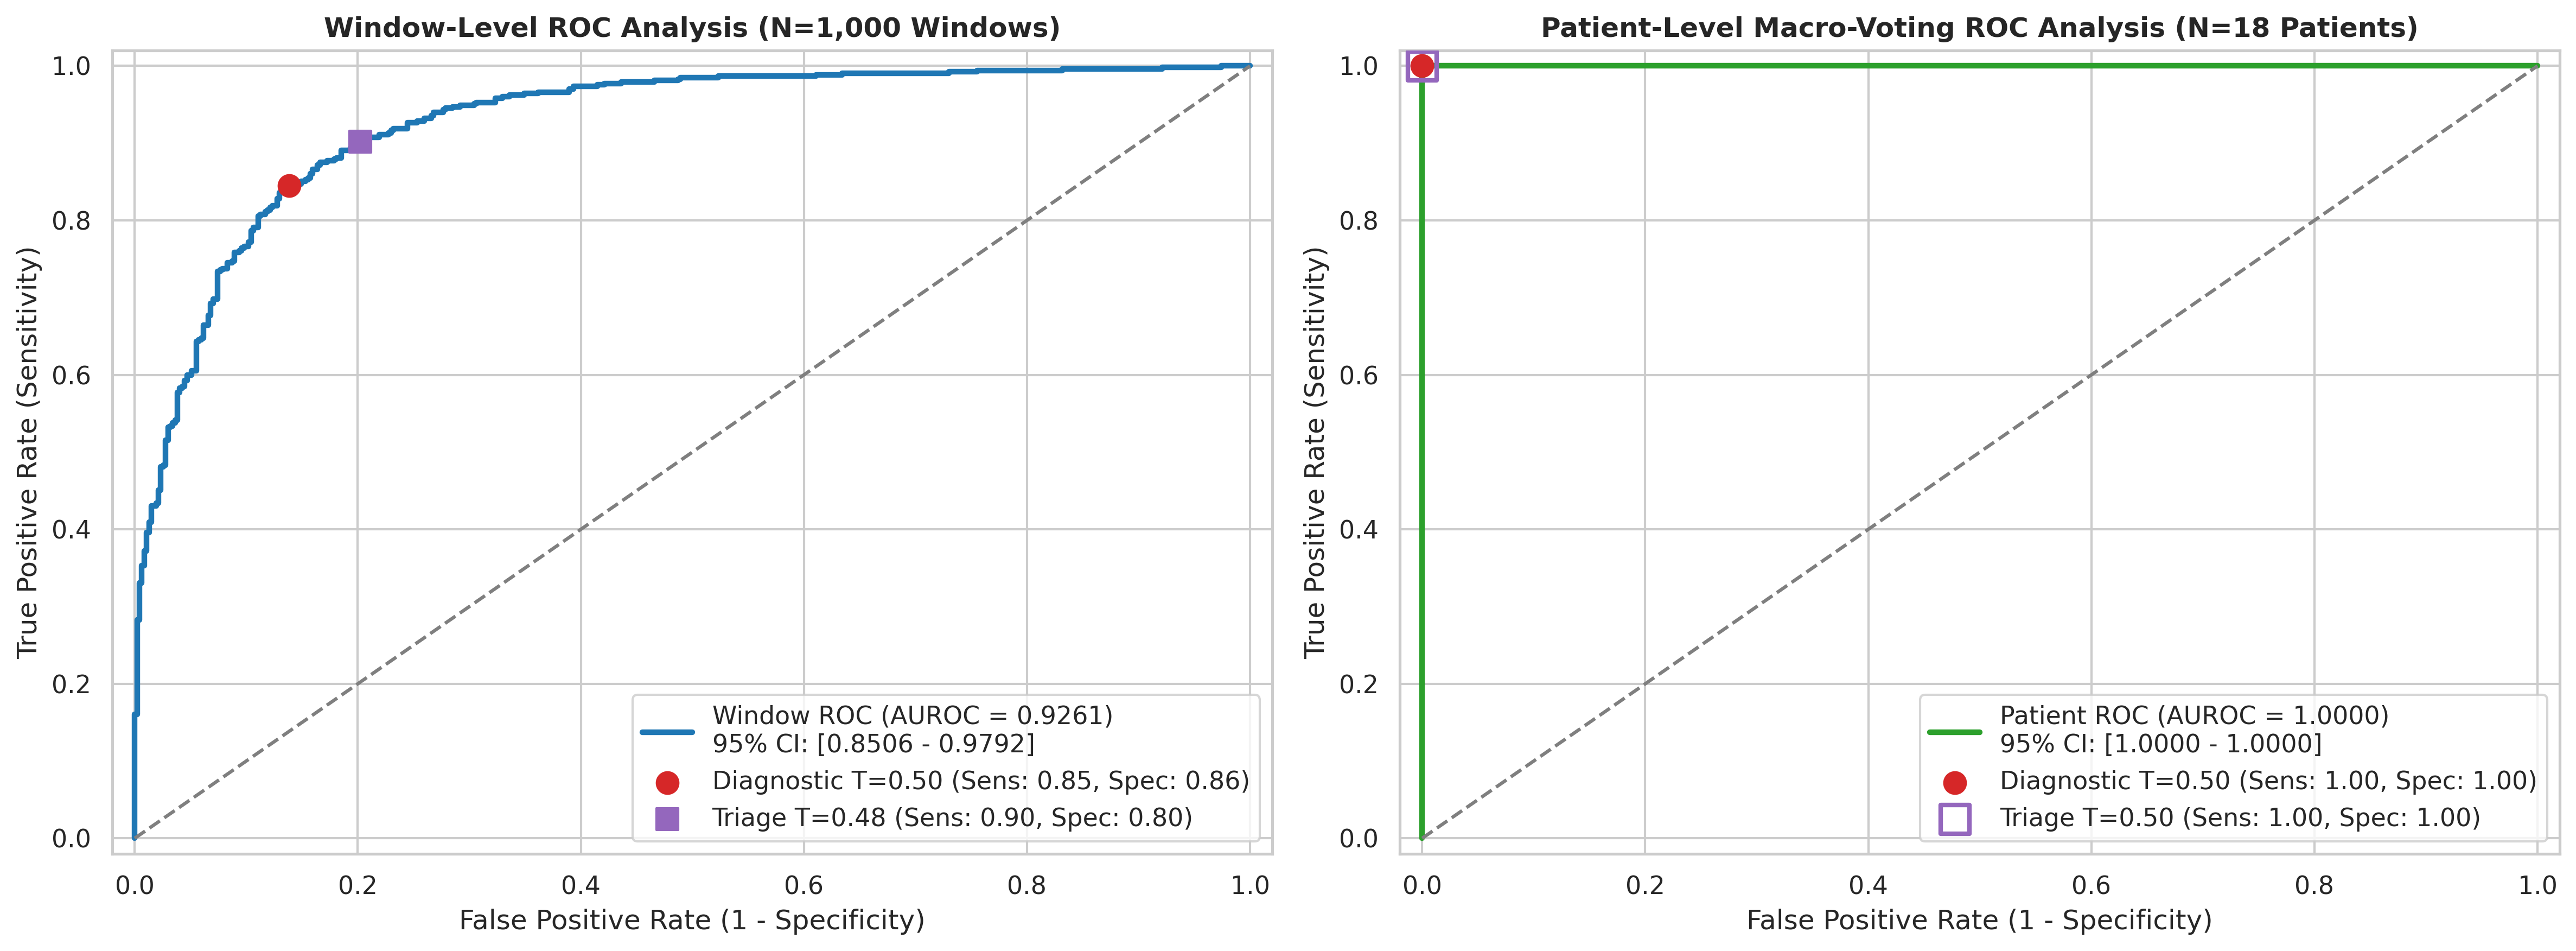

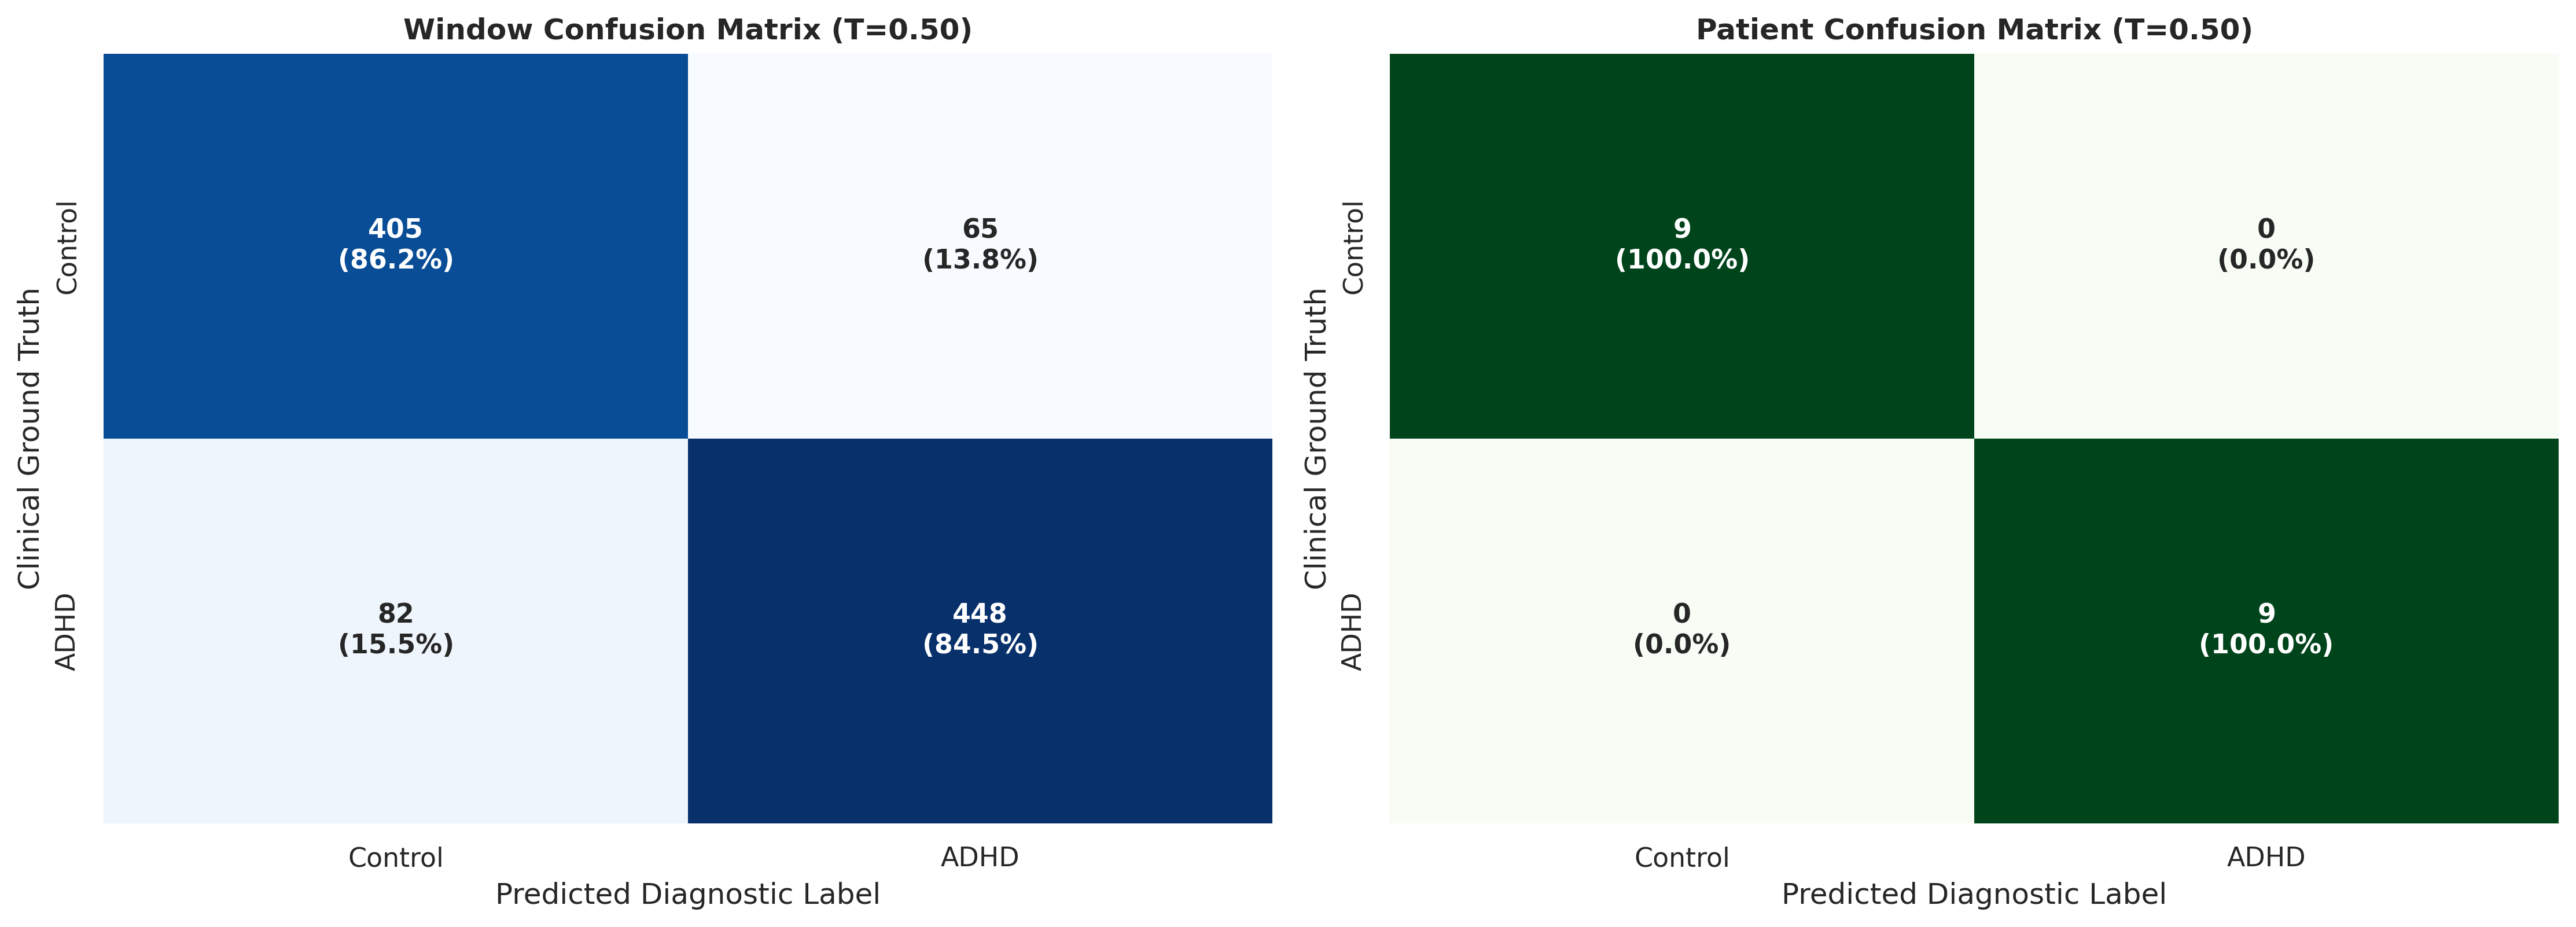

2026-10-23 19:14:23,306 - INFO - Saved publication-grade ROC curves to: outputs/plots/evaluation/roc_curves.png
2026-10-23 19:14:23,307 - INFO - Saved publication-grade confusion matrices to: outputs/plots/evaluation/confusion_matrices.png


In [14]:
# ==============================================================================
# 12. HIGH-RESOLUTION ARTIFACT-FREE PUBLICATION PLOTS (ROC & CONFUSION MATRICES)
# ==============================================================================
fig_roc, axes_roc = plt.subplots(1, 2, figsize=(16, 6), dpi=300)
sns.set_theme(style="whitegrid")

# --- 1. Window-Level ROC Curve ---
axes_roc[0].plot(w_fpr, w_tpr, color='#1f77b4', lw=2.5, 
                 label=f'Window ROC (AUROC = {w_roc_auc:.4f})\n95% CI: [{w_ci_lower:.4f} - {w_ci_upper:.4f}]')
axes_roc[0].plot([0, 1], [0, 1], color='#7f7f7f', lw=1.5, linestyle='--')
axes_roc[0].scatter([1.0 - w_metrics_default['specificity']], [w_metrics_default['sensitivity']], 
                    color='#d62728', s=90, zorder=5, 
                    label=f"Diagnostic T=0.50 (Sens: {w_metrics_default['sensitivity']:.2f}, Spec: {w_metrics_default['specificity']:.2f})")
if w_triage_threshold != 0.5000:
    axes_roc[0].scatter([1.0 - w_metrics_triage['specificity']], [w_metrics_triage['sensitivity']], 
                        color='#9467bd', marker='s', s=90, zorder=5, 
                        label=f"Triage T={w_triage_threshold:.2f} (Sens: {w_metrics_triage['sensitivity']:.2f}, Spec: {w_metrics_triage['specificity']:.2f})")

axes_roc[0].set_title('Window-Level ROC Analysis (N=1,000 Windows)', fontsize=12, fontweight='bold')
axes_roc[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes_roc[0].set_ylabel('True Positive Rate (Sensitivity)')
axes_roc[0].set_xlim([-0.02, 1.02])
axes_roc[0].set_ylim([-0.02, 1.02])
axes_roc[0].legend(loc="lower right", frameon=True)

# --- 2. Patient-Level Macro Soft-Voting ROC Curve ---
axes_roc[1].plot(p_fpr, p_tpr, color='#2ca02c', lw=2.5, 
                 label=f'Patient ROC (AUROC = {p_roc_auc:.4f})\n95% CI: [{p_ci_lower:.4f} - {p_ci_upper:.4f}]')
axes_roc[1].plot([0, 1], [0, 1], color='#7f7f7f', lw=1.5, linestyle='--')

# Plot distinct concentric markers so coincident points at (0, 1) remain distinguishable
axes_roc[1].scatter([1.0 - p_metrics_default['specificity']], [p_metrics_default['sensitivity']], 
                    color='#d62728', s=90, zorder=5, 
                    label=f"Diagnostic T=0.50 (Sens: {p_metrics_default['sensitivity']:.2f}, Spec: {p_metrics_default['specificity']:.2f})")
axes_roc[1].scatter([1.0 - p_metrics_triage['specificity']], [p_metrics_triage['sensitivity']], 
                    facecolors='none', edgecolors='#9467bd', marker='s', s=160, lw=2.0, zorder=6, 
                    label=f"Triage T={p_triage_threshold:.2f} (Sens: {p_metrics_triage['sensitivity']:.2f}, Spec: {p_metrics_triage['specificity']:.2f})")

axes_roc[1].set_title('Patient-Level Macro-Voting ROC Analysis (N=18 Patients)', fontsize=12, fontweight='bold')
axes_roc[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes_roc[1].set_ylabel('True Positive Rate (Sensitivity)')
axes_roc[1].set_xlim([-0.02, 1.02])
axes_roc[1].set_ylim([-0.02, 1.02])
axes_roc[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
roc_curves_path = os.path.join(DIRS["plots_eval"], "roc_curves.png")
plt.savefig(roc_curves_path, dpi=300)
if Config.DISPLAY_INLINE_PLOTS:
    plt.show()
plt.close(fig_roc)

# --- 3. Confusion Matrix Plots ---
fig_cm, axes_cm = plt.subplots(1, 2, figsize=(15, 5.5), dpi=300)

def plot_custom_cm(cm, ax, title, cmap):
    row_sums = cm.sum(axis=1)[:, np.newaxis]
    cm_norm = np.divide(cm.astype('float'), row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums!=0)
    labels = np.empty_like(cm, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            labels[i, j] = f"{cm[i, j]}\n({cm_norm[i, j]*100:.1f}%)"
            
    sns.heatmap(cm, annot=labels, fmt='', cmap=cmap, cbar=False, ax=ax,
                annot_kws={"fontsize": 11, "fontweight": "bold"},
                xticklabels=['Control', 'ADHD'], yticklabels=['Control', 'ADHD'])
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Diagnostic Label')
    ax.set_ylabel('Clinical Ground Truth')

plot_custom_cm(w_metrics_default['confusion_matrix'], axes_cm[0], "Window Confusion Matrix (T=0.50)", 'Blues')
plot_custom_cm(p_metrics_default['confusion_matrix'], axes_cm[1], "Patient Confusion Matrix (T=0.50)", 'Greens')

plt.tight_layout()
cm_path = os.path.join(DIRS["plots_eval"], "confusion_matrices.png")
plt.savefig(cm_path, dpi=300)
if Config.DISPLAY_INLINE_PLOTS:
    plt.show()
plt.close(fig_cm)

logging.info(f"Saved publication-grade ROC curves to: {roc_curves_path}")
logging.info(f"Saved publication-grade confusion matrices to: {cm_path}")

In [15]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
import os

# Standard 10-20 19-channel EEG montage (adjust order if your preprocessing used a different list)
DEFAULT_19_CHANNELS = [
    'Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8',
    'T3',  'C3',  'Cz', 'C4',  'T4',
    'T5',  'P3',  'Pz', 'P4',  'T6',
    'O1',  'O2'
]

def find_target_conv_layer(model):
    """Automatically locates the last 2D/1D Conv layer before transformer/flattening."""
    conv_layers = [layer.name for layer in model.layers if 'conv' in layer.name.lower()]
    if not conv_layers:
        raise ValueError("No convolutional layer found in model.")
    return conv_layers[-1]

def compute_dual_input_gradcam(model, eeg_sample, conn_sample, target_layer_name, class_idx=1):
    """
    Computes Grad-CAM activation map for the EEG spatial-spectral branch.
    eeg_sample: shape (1, 256, 19)
    conn_sample: shape (1, 171)
    class_idx: 1 for ADHD, 0 for Control
    """
    conv_layer = model.get_layer(target_layer_name)
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[conv_layer.output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model([eeg_sample, conn_sample], training=False)
        target_score = predictions[:, class_idx]

    # Compute gradients of the predicted class score w.r.t. feature map activations
    grads = tape.gradient(target_score, conv_outputs)
    
    # Global average pooling across feature dimensions
    if len(conv_outputs.shape) == 4: # Conv2D: (batch, H, W, filters)
        pooled_grads = tf.reduce_mean(grads, axis=(1, 2))
        cam = tf.reduce_sum(tf.multiply(pooled_grads[0], conv_outputs[0]), axis=-1)
    else: # Conv1D: (batch, steps, filters)
        pooled_grads = tf.reduce_mean(grads, axis=1)
        cam = tf.reduce_sum(tf.multiply(pooled_grads[0], conv_outputs[0]), axis=-1)

    cam = tf.maximum(cam, 0.0).numpy()
    norm_denom = np.max(cam) - np.min(cam)
    cam = (cam - np.min(cam)) / (norm_denom + 1e-8)
    return cam, predictions.numpy()[0]

def compute_connectivity_attributions(model, eeg_batch, conn_batch, ch_names, class_idx=1, top_k=10):
    """
    Computes Input * Gradient saliency across the 171 Pearson functional connectivity features.
    """
    conn_tensor = tf.convert_to_tensor(conn_batch, dtype=tf.float32)
    eeg_tensor = tf.convert_to_tensor(eeg_batch, dtype=tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(conn_tensor)
        preds = model([eeg_tensor, conn_tensor], training=False)
        target_scores = preds[:, class_idx]

    grads = tape.gradient(target_scores, conn_tensor)
    attributions = tf.reduce_mean(tf.abs(conn_tensor * grads), axis=0).numpy()

    # Reconstruct 19x19 upper triangle index pairs
    n_ch = len(ch_names)
    pair_labels = []
    for i in range(n_ch):
        for j in range(i + 1, n_ch):
            pair_labels.append(f"{ch_names[i]} - {ch_names[j]}")

    top_indices = np.argsort(attributions)[::-1][:top_k]
    top_pairs = [pair_labels[i] for i in top_indices]
    top_scores = [attributions[i] for i in top_indices]

    return top_pairs, top_scores, pair_labels, attributions

Targeting layer: 'conv2d_4'


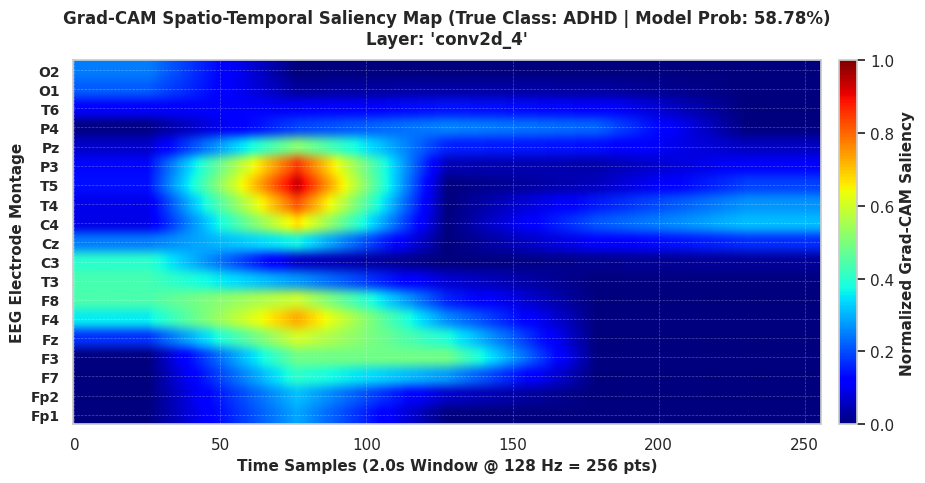

[SAVED] Individual ADHD plot: outputs/figures/gradcam_adhd_individual.png


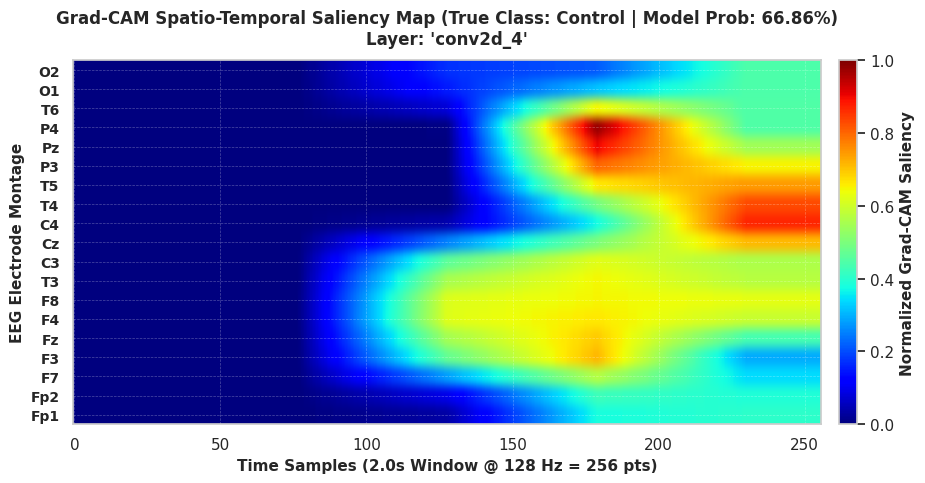

[SAVED] Individual Control plot: outputs/figures/gradcam_control_individual.png


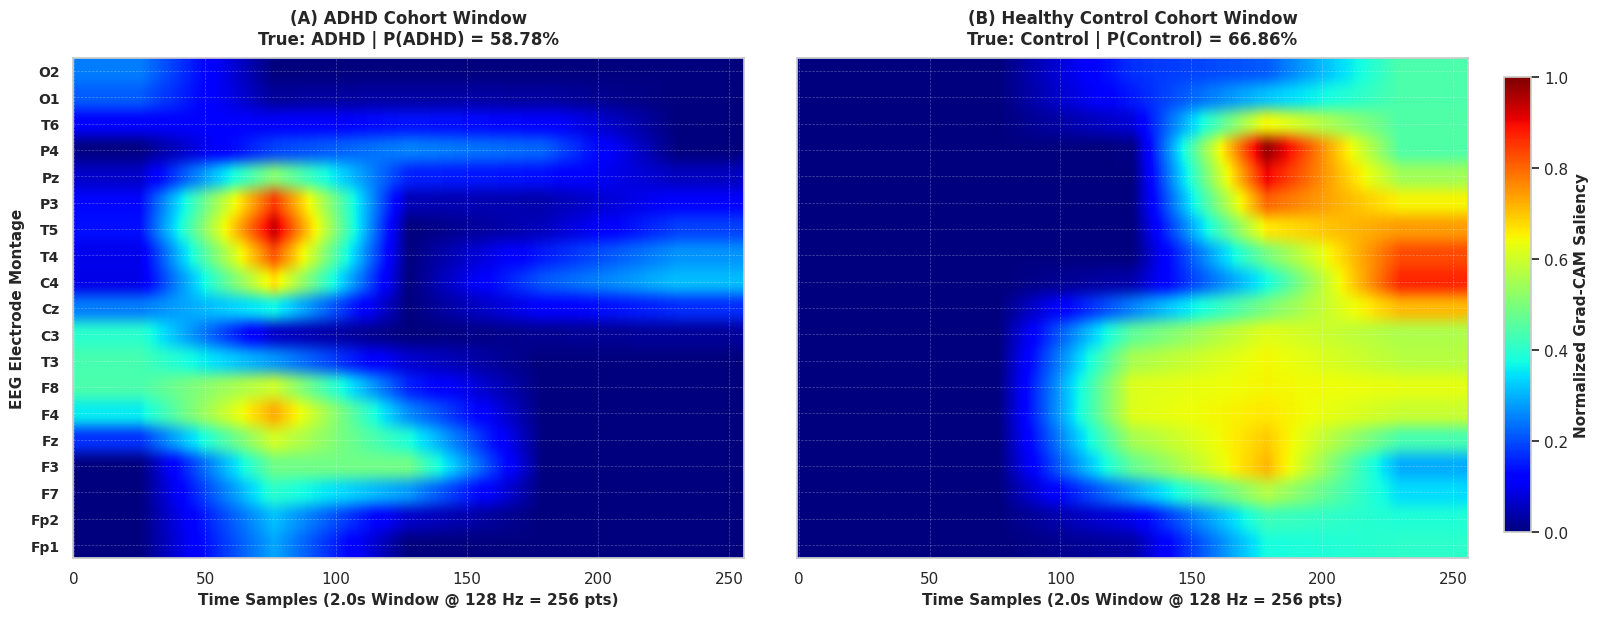

[SAVED] Side-by-side comparison plot: outputs/figures/gradcam_adhd_vs_control_comparison.png


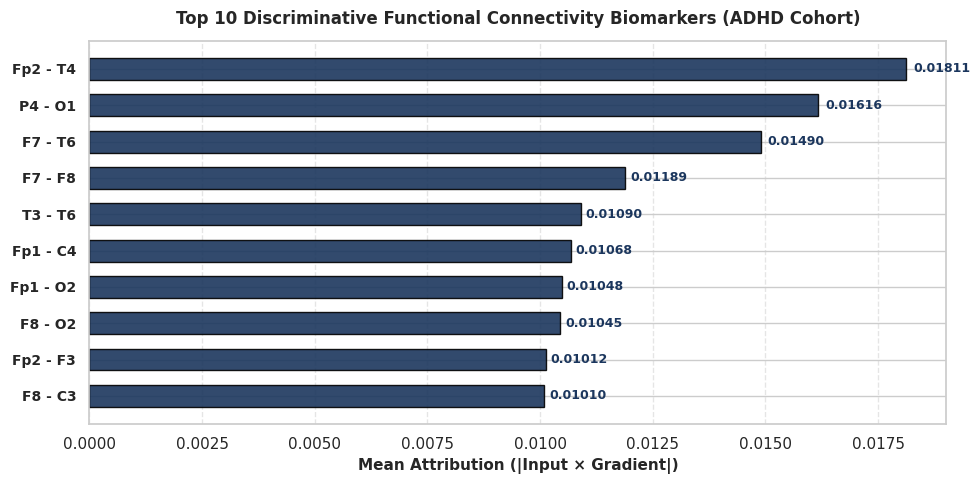

[SAVED] Connectivity Biomarker plot: outputs/figures/top10_connectivity_biomarkers.png


In [16]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ==============================================================================
# 0. CONFIGURATION & DIRECTORIES
# ==============================================================================
OUTPUT_DIR = "outputs/figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEFAULT_19_CHANNELS = [
    'Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8',
    'T3',  'C3',  'Cz', 'C4',  'T4',
    'T5',  'P3',  'Pz', 'P4',  'T6',
    'O1',  'O2'
]

# Helper functions for layer identification and attribution
def find_target_conv_layer(model):
    conv_layers = [layer.name for layer in model.layers if 'conv' in layer.name.lower()]
    if not conv_layers:
        raise ValueError("No convolutional layer found in model.")
    return conv_layers[-1]

def compute_dual_input_gradcam(model, eeg_sample, conn_sample, target_layer_name, class_idx=1):
    conv_layer = model.get_layer(target_layer_name)
    grad_model = tf.keras.Model(
        inputs=model.inputs,
        outputs=[conv_layer.output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model([eeg_sample, conn_sample], training=False)
        target_score = predictions[:, class_idx]

    grads = tape.gradient(target_score, conv_outputs)
    
    if len(conv_outputs.shape) == 4:
        pooled_grads = tf.reduce_mean(grads, axis=(1, 2))
        cam = tf.reduce_sum(tf.multiply(pooled_grads[0], conv_outputs[0]), axis=-1)
    else:
        pooled_grads = tf.reduce_mean(grads, axis=1)
        cam = tf.reduce_sum(tf.multiply(pooled_grads[0], conv_outputs[0]), axis=-1)

    cam = tf.maximum(cam, 0.0).numpy()
    norm_denom = np.max(cam) - np.min(cam)
    cam = (cam - np.min(cam)) / (norm_denom + 1e-8)
    return cam, predictions.numpy()[0]

def compute_connectivity_attributions(model, eeg_batch, conn_batch, ch_names, class_idx=1, top_k=10):
    conn_tensor = tf.convert_to_tensor(conn_batch, dtype=tf.float32)
    eeg_tensor = tf.convert_to_tensor(eeg_batch, dtype=tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(conn_tensor)
        preds = model([eeg_tensor, conn_tensor], training=False)
        target_scores = preds[:, class_idx]

    grads = tape.gradient(target_scores, conn_tensor)
    attributions = tf.reduce_mean(tf.abs(conn_tensor * grads), axis=0).numpy()

    n_ch = len(ch_names)
    pair_labels = []
    for i in range(n_ch):
        for j in range(i + 1, n_ch):
            pair_labels.append(f"{ch_names[i]} - {ch_names[j]}")

    top_indices = np.argsort(attributions)[::-1][:top_k]
    top_pairs = [pair_labels[i] for i in top_indices]
    top_scores = [attributions[i] for i in top_indices]
    return top_pairs, top_scores, pair_labels, attributions


# ==============================================================================
# 1. RESOLVE TEST TENSORS FROM ENVIRONMENT
# ==============================================================================
X_test_arr = None
conn_test_arr = None

for var_name, var_val in list(globals().items()):
    if hasattr(var_val, 'shape'):
        try:
            if var_val.shape == (1000, 256, 19):
                X_test_arr = var_val
            elif var_val.shape == (1000, 171):
                conn_test_arr = var_val
        except Exception:
            pass

if X_test_arr is None or conn_test_arr is None:
    for var_name, var_val in list(globals().items()):
        if isinstance(var_val, tf.data.Dataset) and 'test' in var_name.lower():
            eeg_batches, conn_batches = [], []
            for batch in var_val:
                inputs = batch[0] if isinstance(batch, (tuple, list)) else batch
                if isinstance(inputs, (tuple, list)):
                    eeg_batches.append(inputs[0].numpy())
                    conn_batches.append(inputs[1].numpy())
                elif isinstance(inputs, dict):
                    eeg_batches.append(list(inputs.values())[0].numpy())
                    conn_batches.append(list(inputs.values())[1].numpy())
            X_test_arr = np.concatenate(eeg_batches, axis=0)
            conn_test_arr = np.concatenate(conn_batches, axis=0)
            break

assert X_test_arr is not None and conn_test_arr is not None, "Test arrays could not be located."

if 'y_true_binary' in globals():
    y_test_indices = np.array(y_true_binary)
elif 'y_test' in globals():
    y_test_indices = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 and y_test.shape[1] == 2 else np.array(y_test).flatten()
else:
    raise NameError("Could not locate 'y_true_binary' or 'y_test'.")

conv_layer_name = find_target_conv_layer(model)
print(f"Targeting layer: '{conv_layer_name}'")

# Select representative sample indices
adhd_indices = np.where(y_test_indices == 1)[0]
ctrl_indices = np.where(y_test_indices == 0)[0]

sample_idx_adhd = adhd_indices[0]
sample_idx_ctrl = ctrl_indices[0]

# Prepare samples
eeg_adhd = np.expand_dims(X_test_arr[sample_idx_adhd], axis=0)
conn_adhd = np.expand_dims(conn_test_arr[sample_idx_adhd], axis=0)

eeg_ctrl = np.expand_dims(X_test_arr[sample_idx_ctrl], axis=0)
conn_ctrl = np.expand_dims(conn_test_arr[sample_idx_ctrl], axis=0)

# Compute Grad-CAM activations
cam_adhd, probs_adhd = compute_dual_input_gradcam(
    model, eeg_adhd, conn_adhd, conv_layer_name, class_idx=1
)
cam_adhd_res = cv2.resize(cam_adhd, (19, 256), interpolation=cv2.INTER_LINEAR)

cam_ctrl, probs_ctrl = compute_dual_input_gradcam(
    model, eeg_ctrl, conn_ctrl, conv_layer_name, class_idx=0
)
cam_ctrl_res = cv2.resize(cam_ctrl, (19, 256), interpolation=cv2.INTER_LINEAR)


# ==============================================================================
# DELIVERABLE 1: INDIVIDUAL ADHD AND CONTROL GRAD-CAM PLOTS
# ==============================================================================
# 1A. Individual ADHD Grad-CAM
fig_adhd, ax_adhd = plt.subplots(figsize=(10, 5))
cax1 = ax_adhd.imshow(cam_adhd_res.T, aspect="auto", cmap="jet", origin="lower", vmin=0, vmax=1)
cbar1 = fig_adhd.colorbar(cax1, ax=ax_adhd, pad=0.02)
cbar1.set_label("Normalized Grad-CAM Saliency", fontsize=11, fontweight="bold")
ax_adhd.set_yticks(range(len(DEFAULT_19_CHANNELS)))
ax_adhd.set_yticklabels(DEFAULT_19_CHANNELS, fontsize=10, fontweight="bold")
ax_adhd.set_xlabel("Time Samples (2.0s Window @ 128 Hz = 256 pts)", fontsize=11, fontweight="bold")
ax_adhd.set_ylabel("EEG Electrode Montage", fontsize=11, fontweight="bold")
ax_adhd.set_title(
    f"Grad-CAM Spatio-Temporal Saliency Map (True Class: ADHD | Model Prob: {probs_adhd[1]:.2%})\n"
    f"Layer: '{conv_layer_name}'", 
    fontsize=12, fontweight="bold", pad=12
)
ax_adhd.grid(color="white", linestyle="--", linewidth=0.5, alpha=0.3)
plt.tight_layout()
adhd_indiv_path = os.path.join(OUTPUT_DIR, "gradcam_adhd_individual.png")
fig_adhd.savefig(adhd_indiv_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Individual ADHD plot: {adhd_indiv_path}")

# 1B. Individual Control Grad-CAM
fig_ctrl, ax_ctrl = plt.subplots(figsize=(10, 5))
cax2 = ax_ctrl.imshow(cam_ctrl_res.T, aspect="auto", cmap="jet", origin="lower", vmin=0, vmax=1)
cbar2 = fig_ctrl.colorbar(cax2, ax=ax_ctrl, pad=0.02)
cbar2.set_label("Normalized Grad-CAM Saliency", fontsize=11, fontweight="bold")
ax_ctrl.set_yticks(range(len(DEFAULT_19_CHANNELS)))
ax_ctrl.set_yticklabels(DEFAULT_19_CHANNELS, fontsize=10, fontweight="bold")
ax_ctrl.set_xlabel("Time Samples (2.0s Window @ 128 Hz = 256 pts)", fontsize=11, fontweight="bold")
ax_ctrl.set_ylabel("EEG Electrode Montage", fontsize=11, fontweight="bold")
ax_ctrl.set_title(
    f"Grad-CAM Spatio-Temporal Saliency Map (True Class: Control | Model Prob: {probs_ctrl[0]:.2%})\n"
    f"Layer: '{conv_layer_name}'", 
    fontsize=12, fontweight="bold", pad=12
)
ax_ctrl.grid(color="white", linestyle="--", linewidth=0.5, alpha=0.3)
plt.tight_layout()
ctrl_indiv_path = os.path.join(OUTPUT_DIR, "gradcam_control_individual.png")
fig_ctrl.savefig(ctrl_indiv_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Individual Control plot: {ctrl_indiv_path}")


# ==============================================================================
# DELIVERABLE 2: SIDE-BY-SIDE COMPARATIVE GRAD-CAM PLOT
# ==============================================================================
fig_comp, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(18, 6.5), sharey=True)

# Panel A: ADHD
im_a = ax_left.imshow(cam_adhd_res.T, aspect="auto", cmap="jet", origin="lower", vmin=0, vmax=1)
ax_left.set_yticks(range(len(DEFAULT_19_CHANNELS)))
ax_left.set_yticklabels(DEFAULT_19_CHANNELS, fontsize=10, fontweight="bold")
ax_left.set_xlabel("Time Samples (2.0s Window @ 128 Hz = 256 pts)", fontsize=11, fontweight="bold")
ax_left.set_ylabel("EEG Electrode Montage", fontsize=11, fontweight="bold")
ax_left.set_title(
    f"(A) ADHD Cohort Window\nTrue: ADHD | P(ADHD) = {probs_adhd[1]:.2%}",
    fontsize=12, fontweight="bold", pad=10
)
ax_left.grid(color="white", linestyle="--", linewidth=0.5, alpha=0.3)

# Panel B: Control
im_b = ax_right.imshow(cam_ctrl_res.T, aspect="auto", cmap="jet", origin="lower", vmin=0, vmax=1)
ax_right.set_xlabel("Time Samples (2.0s Window @ 128 Hz = 256 pts)", fontsize=11, fontweight="bold")
ax_right.set_title(
    f"(B) Healthy Control Cohort Window\nTrue: Control | P(Control) = {probs_ctrl[0]:.2%}",
    fontsize=12, fontweight="bold", pad=10
)
ax_right.grid(color="white", linestyle="--", linewidth=0.5, alpha=0.3)

# Shared Colorbar
cbar_ax = fig_comp.add_axes([0.92, 0.15, 0.015, 0.7])
cbar_comp = fig_comp.colorbar(im_b, cax=cbar_ax)
cbar_comp.set_label("Normalized Grad-CAM Saliency", fontsize=11, fontweight="bold")

plt.subplots_adjust(right=0.90, wspace=0.08)
comparison_path = os.path.join(OUTPUT_DIR, "gradcam_adhd_vs_control_comparison.png")
fig_comp.savefig(comparison_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Side-by-side comparison plot: {comparison_path}")


# ==============================================================================
# DELIVERABLE 3: FUNCTIONAL CONNECTIVITY ATTRIBUTION PLOT
# ==============================================================================
adhd_eeg_cohort = X_test_arr[adhd_indices]
adhd_conn_cohort = conn_test_arr[adhd_indices]

top_pairs, top_scores, all_pairs, all_scores = compute_connectivity_attributions(
    model=model,
    eeg_batch=adhd_eeg_cohort,
    conn_batch=adhd_conn_cohort,
    ch_names=DEFAULT_19_CHANNELS,
    class_idx=1,
    top_k=10
)

fig_conn, ax_conn = plt.subplots(figsize=(10, 5))
y_positions = np.arange(len(top_pairs))
bars = ax_conn.barh(y_positions, top_scores[::-1], color="#1B365D", edgecolor="black", alpha=0.9, height=0.6)

ax_conn.set_yticks(y_positions)
ax_conn.set_yticklabels(top_pairs[::-1], fontsize=10, fontweight="bold")
ax_conn.set_xlabel("Mean Attribution (|Input × Gradient|)", fontsize=11, fontweight="bold")
ax_conn.set_title("Top 10 Discriminative Functional Connectivity Biomarkers (ADHD Cohort)", fontsize=12, fontweight="bold", pad=12)
ax_conn.grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars:
    width = bar.get_width()
    ax_conn.text(
        width + (width * 0.01),
        bar.get_y() + bar.get_height() / 2,
        f"{width:.5f}",
        va='center',
        ha='left',
        fontsize=9,
        color="#1B365D",
        fontweight="bold"
    )

plt.tight_layout()
conn_plot_path = os.path.join(OUTPUT_DIR, "top10_connectivity_biomarkers.png")
fig_conn.savefig(conn_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[SAVED] Connectivity Biomarker plot: {conn_plot_path}")